# openpilot supercombo on KITScenes: change the image, see the plan

This is a short companion to [the image-calibration notebook](openpilot_drv_supcombo_kitscenes_image_calibration.ipynb), which measured about a hundred image settings on ten turns. This one runs no sweeps. You edit one config and see what it does:

1. **Five turns, as the recorded run planned them.** For each turn:
    - the four images the model was given (each view's two frames);
    - the GT and the plan drawn on the keyframe;
    - the warps that cut each view out of the camera image, and the road's homography into each view.
2. **One turn, `FOCUS`: how the heights and speeds are measured.** Both the real values and the values the model reads.
3. **`CONFIG`, an image change, on that turn.** Edit it and re-run the cell. The model plans again, and the new plan is drawn beside stock's. A `noise` row shows how much a half-pixel shift alone changes each number.
4. **The same config on all five turns**, scored against stock on ADE, alignment with the GT and the speed profile. Each change is judged against a noise floor.

**How it runs**
- **The code** is in [`openpilot_drv_supcombo_image_tweak_lib.py`](openpilot_drv_supcombo_image_tweak_lib.py), next to this notebook. Restart the kernel after editing it.
- **Paddock never imports a model, and neither does this notebook.**
    - The model runs in [`openpilot_drv_supcombo_image_node.py`](openpilot_drv_supcombo_image_node.py). It is the stock adapter; only the way it makes the warps and tensors is changed.
    - The node runs in openpilot's own interpreter, the same way `paddock run` launches a model. The notebook sends it matrices and lookup tables over localhost.
    - The checks before part 3 show that, with no config, the node is the stock adapter bit for bit.
- **It runs on CPU by default.** The nodes start the first time they are needed, one per turn.
- **Every result is cached** under `{runs}/kitscenes/_analysis/openpilot/image_tweak/`. The cache key is the matrices sent, the sample, the device and a hash of the code. Running the same config again costs nothing.

**The committed outputs are stock.** `CONFIG` leaves the image unchanged, so parts 3 and 4 show stock against itself. They were made on CPU by `.venv/bin/jupyter execute --inplace`.

In [1]:
import sys

import pandas as pd

from paddock.config import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT / "tools/models/openpilot/analysis"))  # the lib, beside this notebook
import openpilot_drv_supcombo_image_tweak_lib as T

pd.set_option("display.max_columns", 50)  # part 4's per-turn table has 31 columns

## Parameters

- **`SCENES`**: the five turns. Wherever a cell takes a key, the key can be:
    - a sample id;
    - a label such as `"03ed2585/40"` (the first 8 characters of the scene id, then the keyframe);
    - a unique prefix of either.
- **`FOCUS`**: the turn that parts 2 and 3 work on.
- **`RUN_ID`**: the recorded stock run that part 1 draws.
- **`DEVICE`**: `"cpu"`, or `"cuda"` if a GPU is free. **`NODES`** is the number of model processes; **`THREADS`** is the threads each one uses.
- **`HEIGHT`**: the camera's real height. It is used to draw the road and by the knobs that move the camera. One of:
    - `"context"`: the map's height for each scene, near 1.88 m;
    - `"harness"`: about 2.0 m;
    - a number in metres.
- **`OVERRIDES`**: tag parameters for the turn classes, for example `{"curv_under": 0.6}`.
- **`RECOMPUTE`**: ignore the cached results.
- **`OVERLAY`**: where the GT and the plans are drawn.
    - `"img"`: the keyframe of the narrow view.
    - Add `"big_img"` for the wide view, or `"camera"` for the photo.

In [2]:
SCENES = [
    "dbba76d9-91ec-b44f-f3d3-6348d55f7849/130",  # left in 18 m: not planned
    "5bf1c78c-46c7-2e4d-7295-00a1de902965/40",  # left in 18 m: the wrong way
    "8c501afb-5a9b-e881-1c7d-99c21f39b1cc/40",  # left in 17 m: understeer
    "03ed2585-0729-92ad-98af-fdd9ac1c3a80/40",  # right in 28 m: understeer by slowing; the worst ADE
    "b8002a79-ac44-b7bb-c7d6-0136e49e016f/40",  # right in 64 m at 12.8 m/s: matched (a control)
]
FOCUS = "03ed2585/40"
RUN_ID = "20260930T154018-242869"  # the open-loop notebook's stock re-run
DEVICE = "cpu"
NODES, THREADS = 5, 8
HEIGHT = "context"
OVERRIDES = {}
RECOMPUTE = False
OVERLAY = ("img",)  # on 4 of the 5 turns img shows little or none of the path; add "big_img" or "camera"

lab = T.Lab(
    SCENES,
    RUN_ID,
    device=DEVICE,
    nodes=NODES,
    threads=THREADS,
    height=HEIGHT,
    overrides=OVERRIDES,
    recompute=RECOMPUTE,
)

5 turns; code 133d484051 (openpilot 555f48c5d); model on cpu, 5 node(s); cache {runs}/kitscenes/_analysis/openpilot/image_tweak


## 1 Five turns, as the recorded run planned them

These five come from the image-calibration notebook's ten. They cover three ways stock gets a near turn wrong (no turn, the wrong way, too little), plus one far turn it gets right:

| turn | route | speed | stock |
|---|---|---|---|
| dbba76d9/130 | left in 18 m | 3.9 m/s | does not plan the turn |
| 5bf1c78c/40 | left in 18 m | 4.2 m/s | turns the wrong way |
| 8c501afb/40 | left in 17 m | 4.2 m/s | turns too little |
| 03ed2585/40 | right in 28 m | 4.9 m/s | keeps to the GT's path but slows, so by 3 s it has turned too little; the worst ADE |
| b8002a79/40 | right in 64 m | 12.8 m/s | matches the GT's turn over 3 s |

The columns, here and in every table below:
- **`mode`**: the open-loop notebook's turn class. The first match wins:
    - `not_planned`: the plan's heading changes by less than 15° over its 10 s;
    - `wrong_way`: it turns 15° or more away from the route;
    - otherwise the class compares the plan's turn with the GT's over 3 s: `understeer` under 0.7 of it, `oversteer` 1.3 or more, `matched` in between.
- **`ade`**: the benchmark's score, the mean distance from the GT over 3 s (m).
- **`ade_long`**: the same over the GT's whole length, up to 10 s.
- **`lat`**: the benchmark's mean lateral error over 3 s (m), between the plan and the GT at the same time.
- **`path_err`**: the mean distance from the plan's waypoints over 3 s to the GT's path, wherever along it they fall (m). It ignores timing: a plan on the GT's line scores 0, however slowly it drives it.
- **`dpsi`, `gt_dpsi`**: the plan's and the GT's heading change over 3 s (deg). Positive is toward the route.
- **`turn_frac`**: the plan's share of the GT's turn, over the GT's whole length.
- **`speed_rmse`**: the RMS difference between the plan's and the GT's speeds over 3 s, per 0.5 s step (m/s).
- **`v0_ratio`**: the speed of the plan's first step over the GT's.
- **`head_ratio`**: the pose head's speed over the car's.
- **`plan_v0`**: the plan's own start speed (m/s).
- **`cam_h`, `h_map`**: the camera height the model reads, and the real height from the map (m). Part 2 says how each is measured.

In [3]:
lab.recorded_table().round(3)

,route,v,mode,ade,ade_long,lat,path_err,dpsi,gt_dpsi,turn_frac,speed_rmse,v0_ratio,head_ratio,plan_v0,cam_h,h_map
key,,,,,,,,,,,,,,,,
dbba76d9/130,left in 18 m,3.867,not_planned,2.318,10.124,1.896,0.851,1.095,61.474,-0.002,0.946,0.798,0.896,3.352,1.413,1.931
5bf1c78c/40,left in 18 m,4.175,wrong_way,1.716,15.603,0.859,0.336,-4.429,34.047,-0.965,1.223,0.805,0.766,3.170,1.383,1.976
8c501afb/40,left in 17 m,4.211,understeer,0.743,15.503,0.465,0.254,41.023,62.876,0.371,0.411,0.792,0.722,3.012,1.384,1.856
03ed2585/40,right in 28 m,4.925,understeer,2.858,13.512,1.873,0.191,27.856,52.506,1.007,2.441,0.899,0.708,4.402,1.361,1.867
b8002a79/40,right in 64 m,12.751,matched,2.137,12.633,0.098,0.383,13.067,13.261,0.622,1.367,0.915,0.883,11.555,1.633,1.878


Each figure shows one turn:
- **Top row:**
    - the camera's keyframe, with the outlines of img (yellow) and big_img (cyan) and the road at its real height;
    - the paths seen from above;
    - the speed and the heading at each 0.5 s step.
- **Bottom row:** the four images the model was given. Each view has two frames: the frame 0.2 s before the keyframe, then the keyframe. The GT and the plan are drawn on the keyframe of each `OVERLAY` view, placed where the real camera sees them.

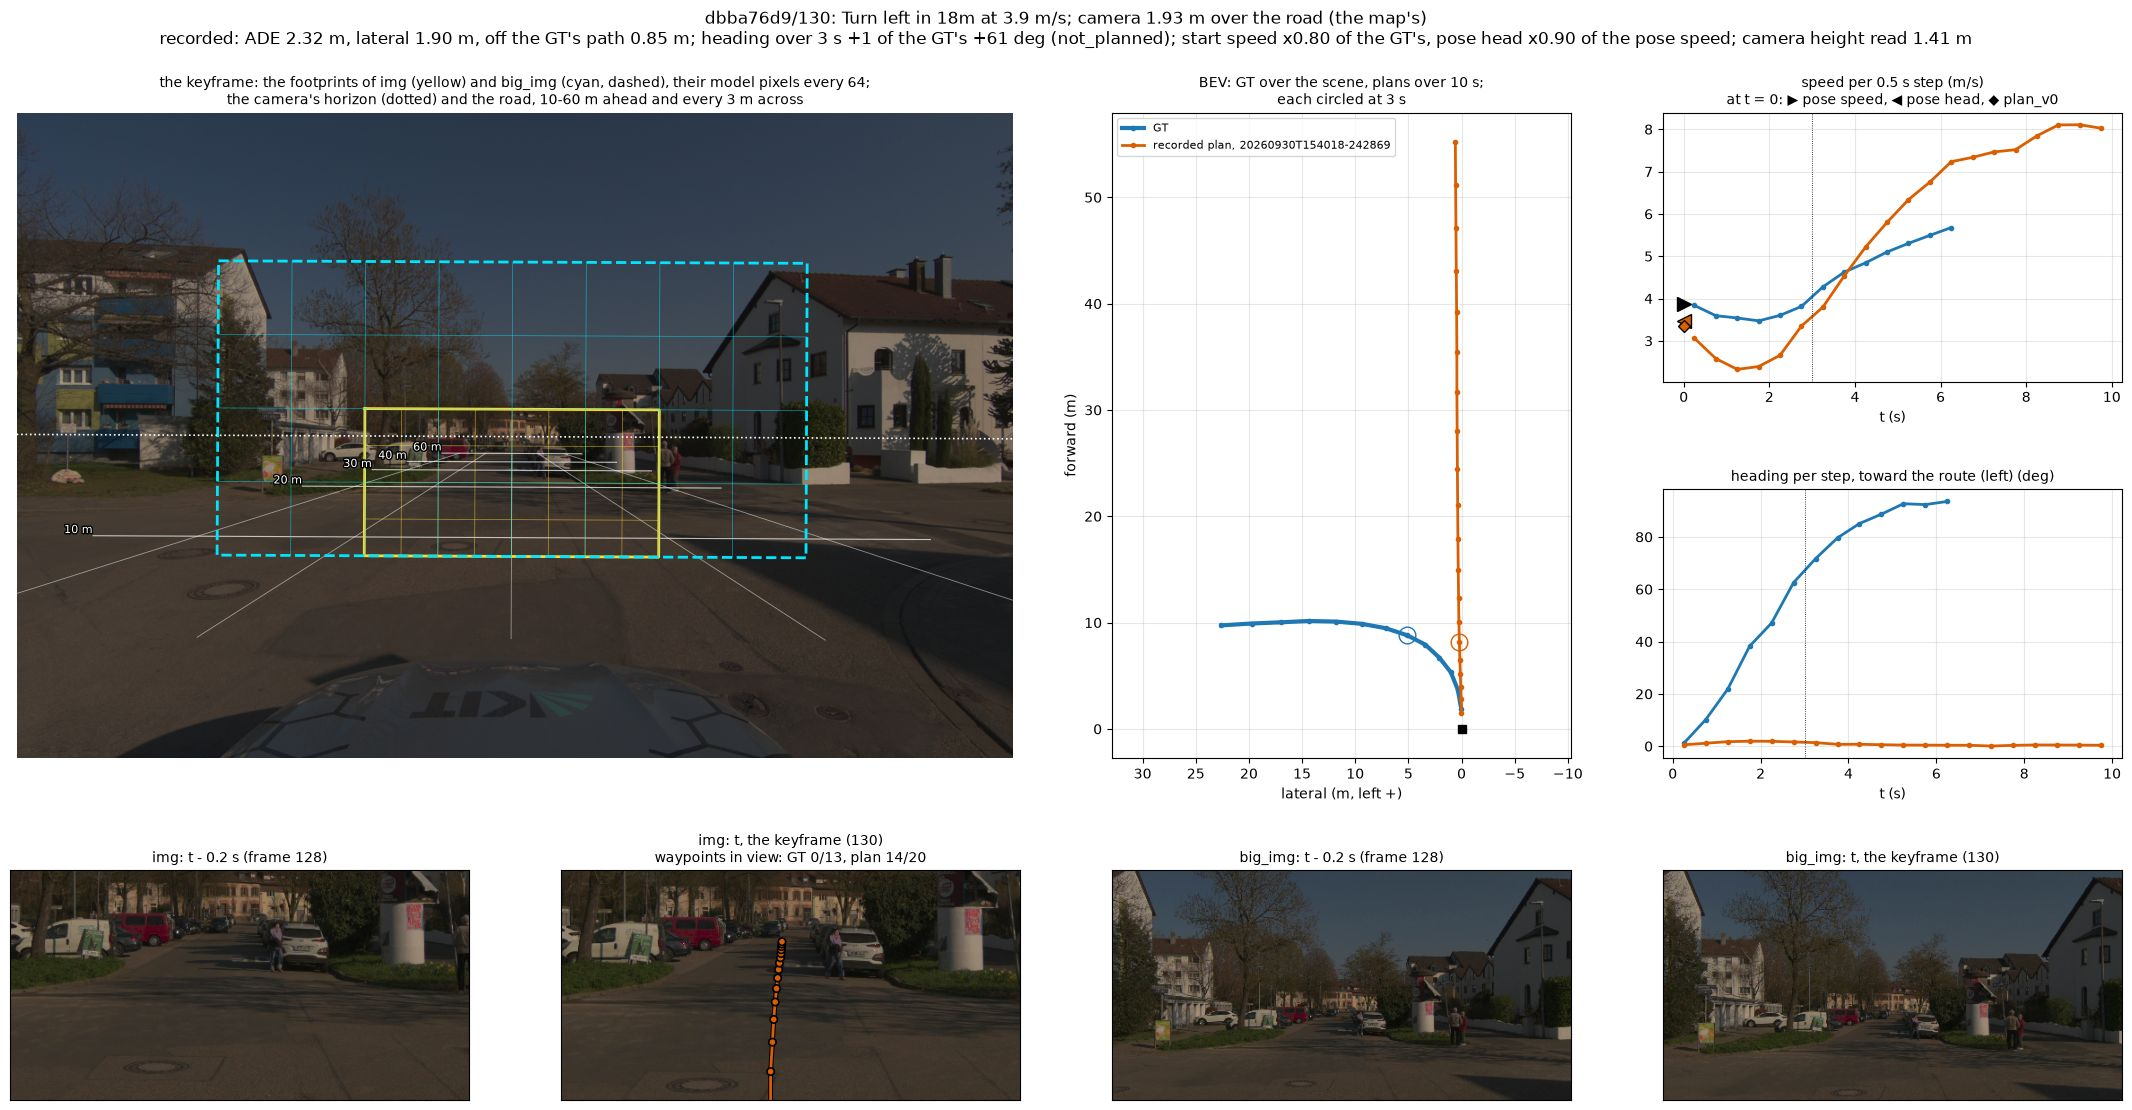

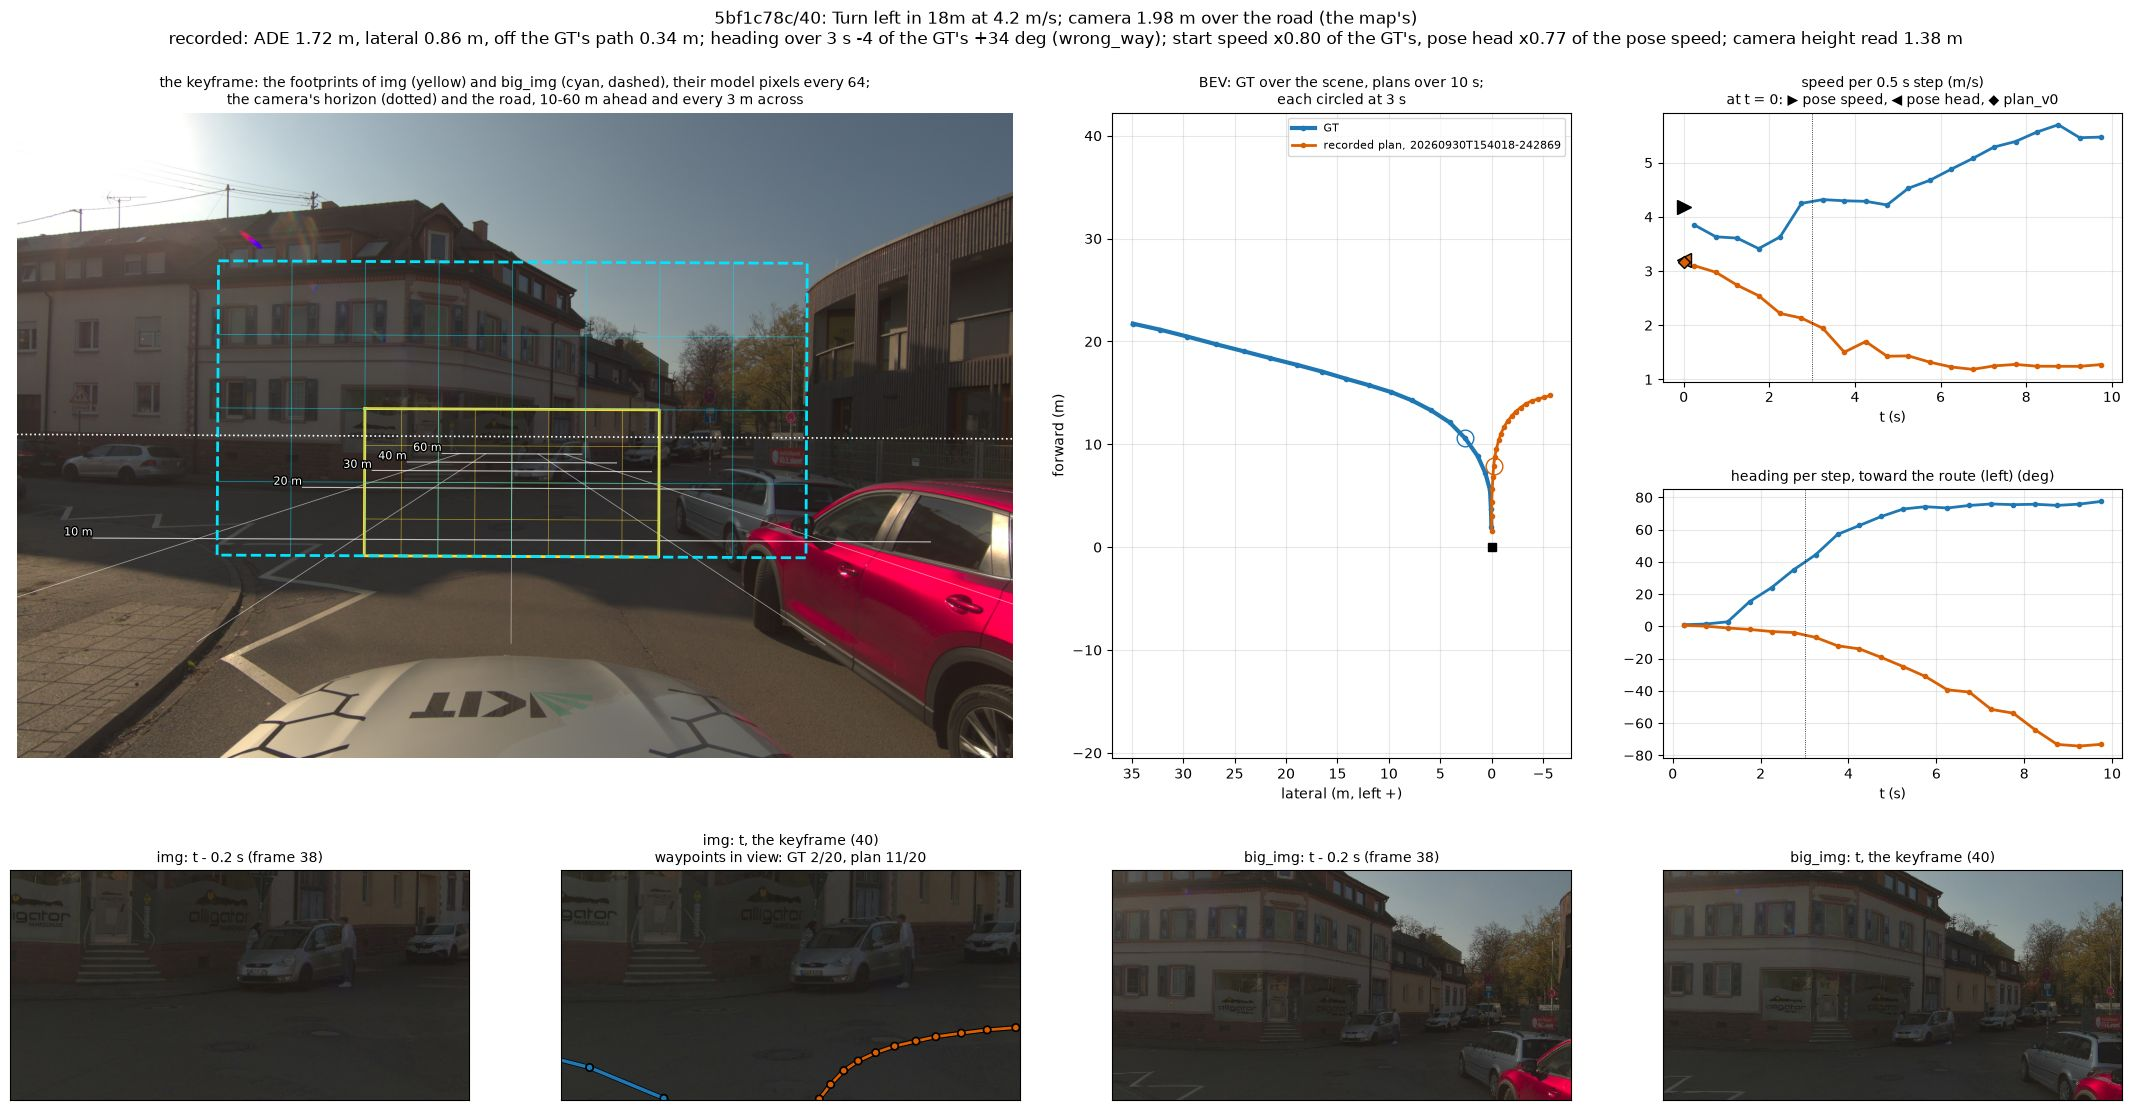

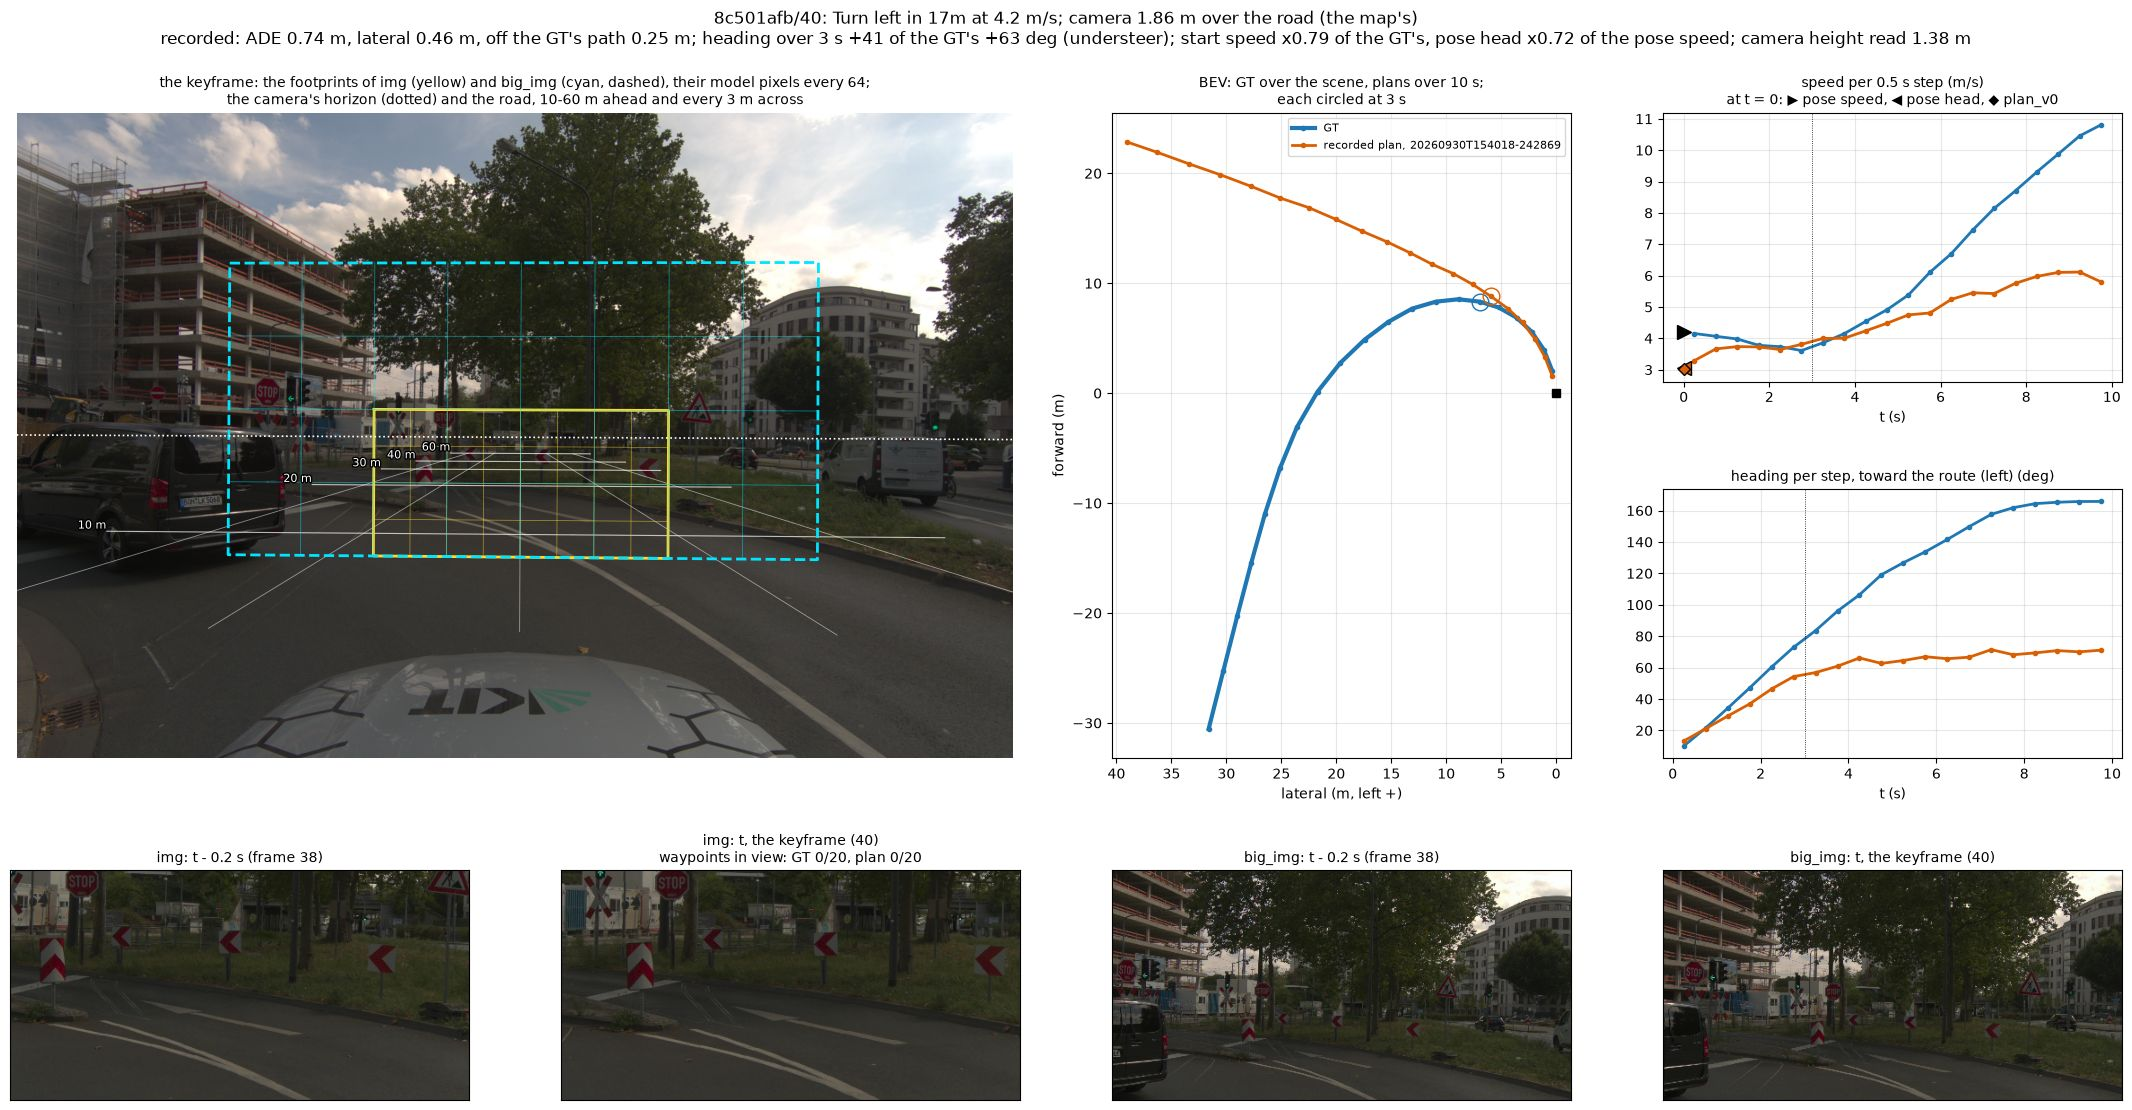

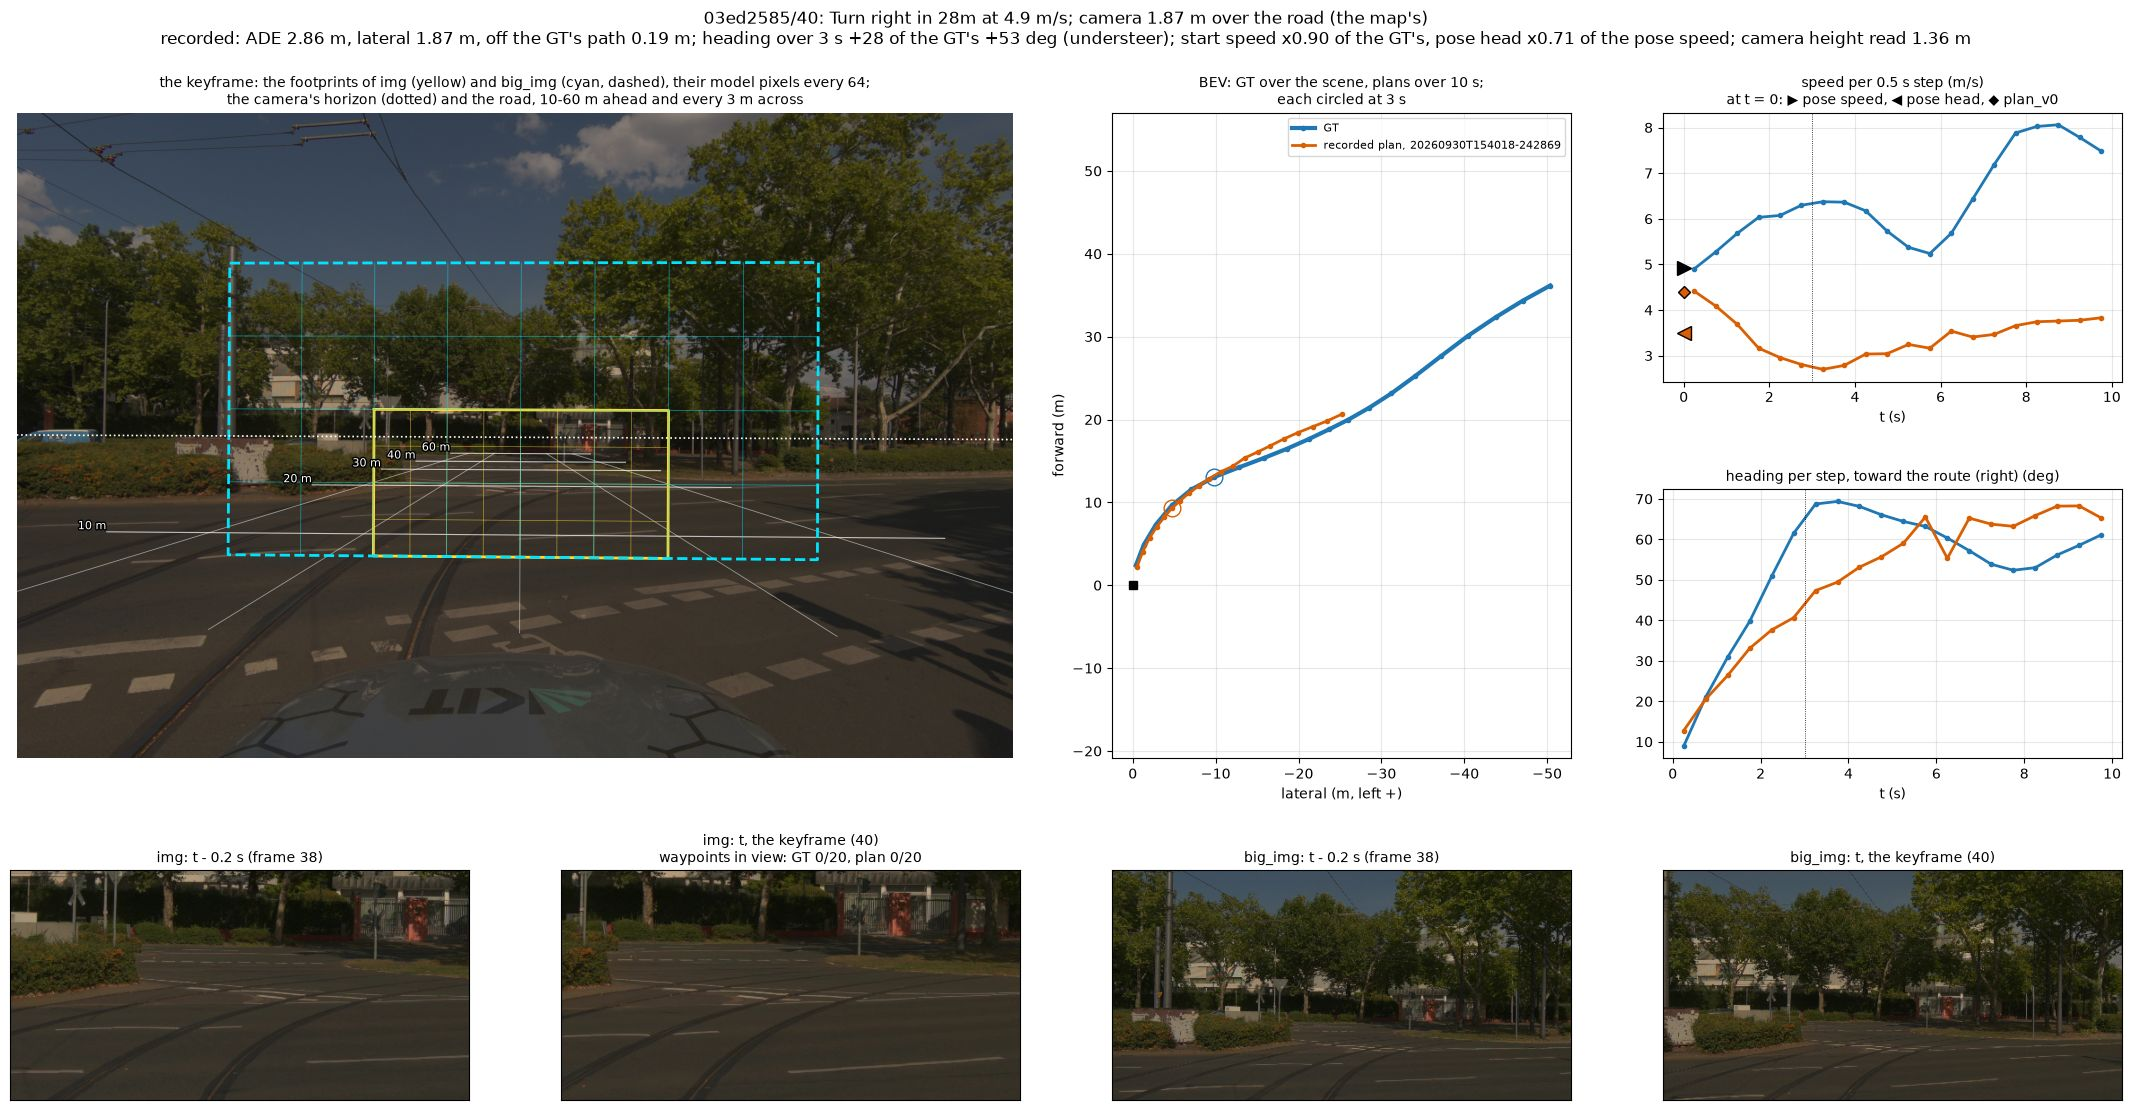

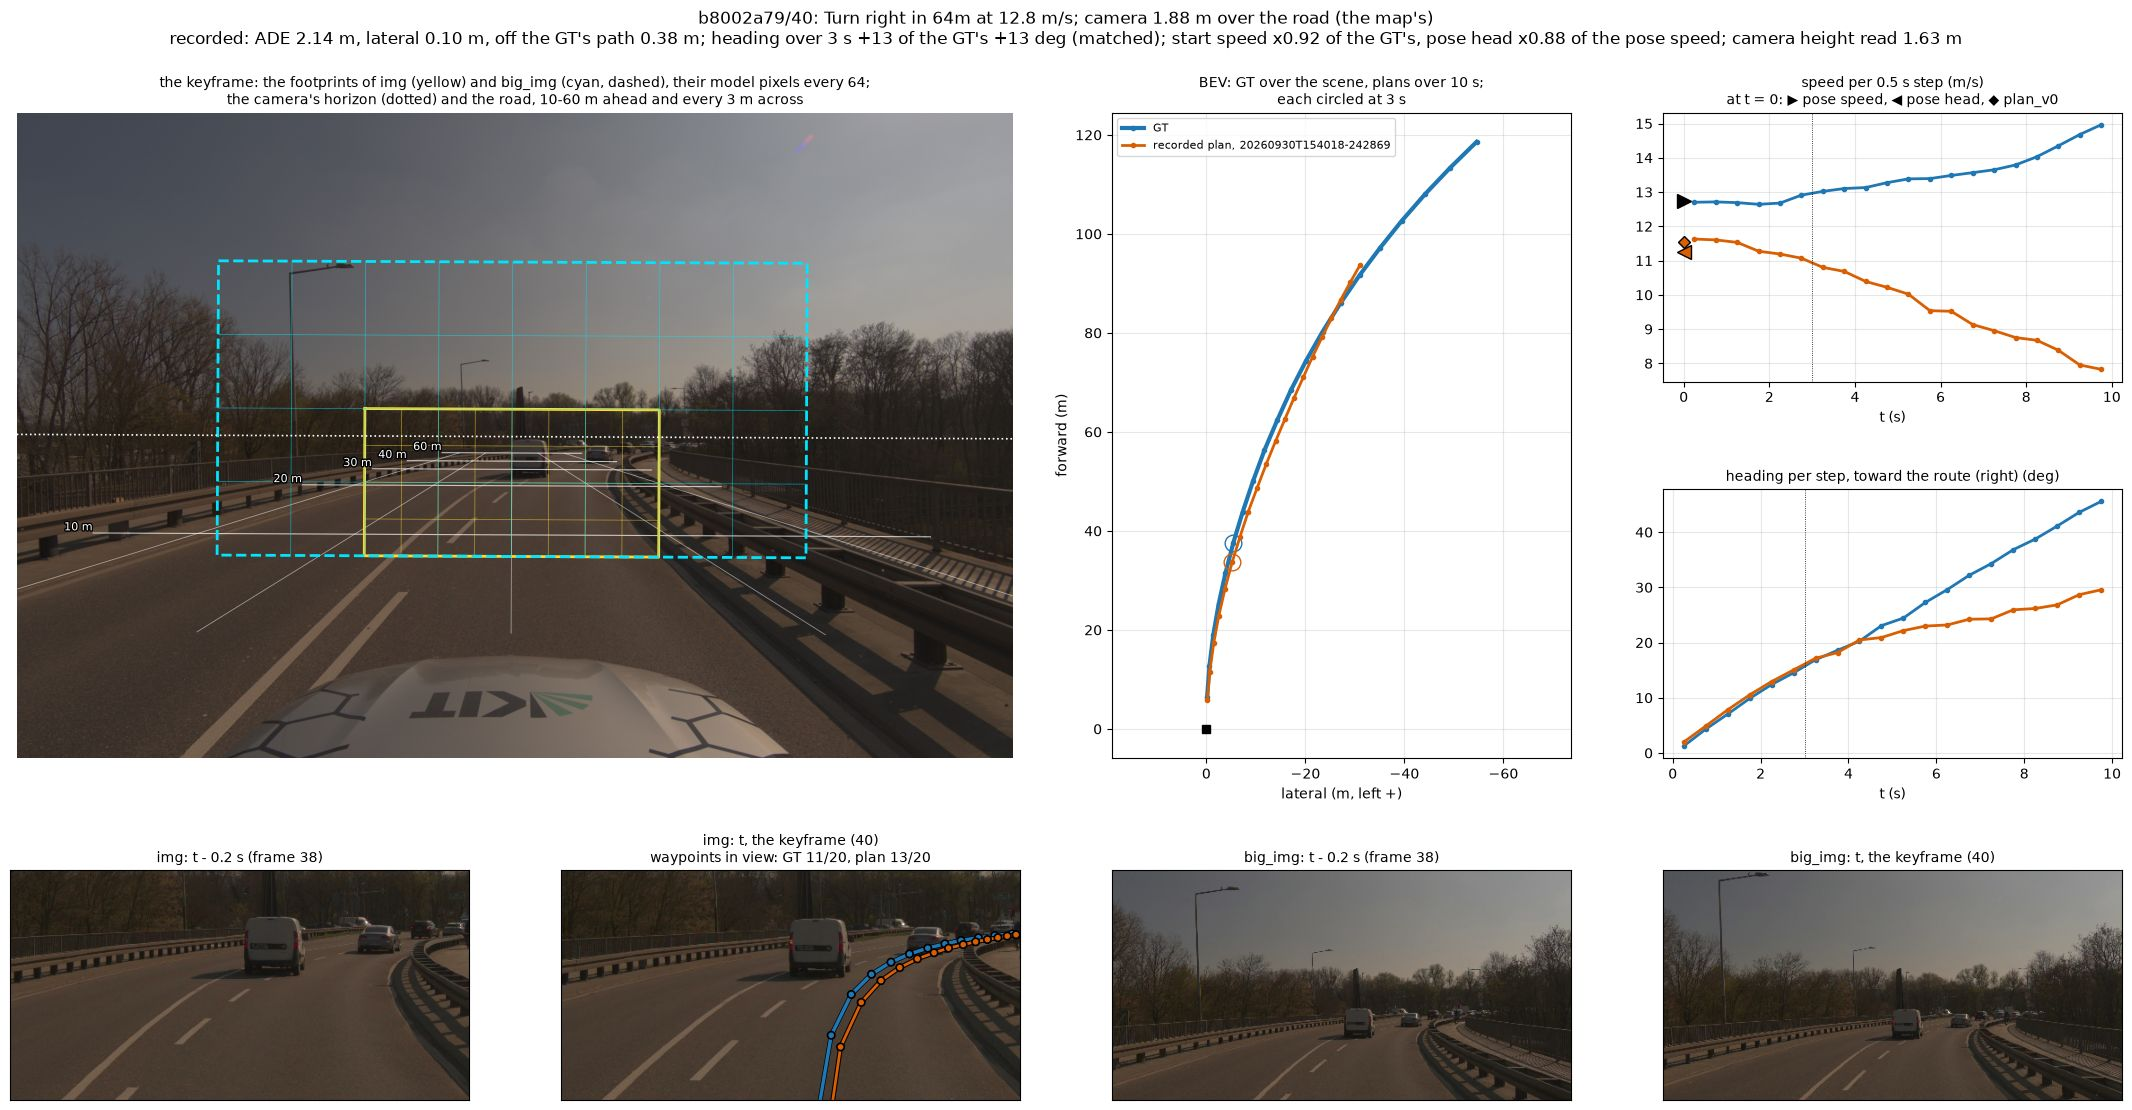

In [4]:
for key in lab.keys:
    lab.show_recorded(key, overlay=OVERLAY)

**How much of the path img sees.** Each view's title counts the waypoints inside it. On four of the five turns, img shows few or none of the GT's waypoints:
- at 4–5 m/s, roughly the first 2 s of the path are nearer than img's bottom edge, which meets the road about 8 m ahead;
- after that, the turn takes the path out of img's ±16°.

Only b8002a79/40 keeps its path inside img: 11 of its 20 GT waypoints, including 5 of the 6 within 3 s. That turn is at 12.8 m/s on a gentle bend.

To draw the path where it can be seen, set `OVERLAY = ("img", "big_img", "camera")`. big_img spans ±29° across, and the photo shows the camera's whole field of view.

### The warp and the homographies

The model never sees the camera's image directly. Each view is cut out of it by a 3 × 3 homography, one per view for each car:

`W[view] = camera_from_calib @ calib_from_model[view]`

- **`calib_from_model[view]`** is openpilot's own and is the same for every car. It maps a model pixel to a ray in the calibrated frame (x forward, y right, z down).
- **`camera_from_calib`** belongs to the car: the camera's intrinsics K, times its mounting rotation (the roll, pitch and yaw in calib.json).

So W contains a rotation and a focal change, but no camera height. The height enters through the road's homography into each view:

`inv(W[view]) @ G`, where `G = K @ [r1 r2 t]`

G maps a road point (x, y, 1) to a camera pixel, for a camera h metres above the road.

The cell below shows three things:
1. the matrices for `FOCUS`;
2. the road grid drawn through each view's homography, on all five turns;
3. a table of each turn's camera.

Part 3's image changes are applied between the two factors of W:

`camera_from_calib @ calib @ calib_from_model[view]`

03ed2585/40, the stock warps and the road's homographies:

camera_from_calib: calibrated ray -> camera pixel (the camera's K, rotated by its rpy)
[[       1771        1811      -11.82]
 [       1142       -10.9        1839]
 [     0.9999    -0.01698   -0.001911]]

calib_from_model[img]: model pixel -> calibrated ray (openpilot's own; the same for every car)
[[  3.388e-21   4.665e-18           1]
 [   0.001099  -1.312e-18     -0.2813]
 [ -2.255e-20    0.001099    -0.05231]]

calib_from_model[big_img]: model pixel -> calibrated ray (openpilot's own; the same for every car)
[[  3.388e-21           0           1]
 [   0.002198          -0     -0.5626]
 [ -6.663e-20    0.002198     -0.3336]]

W[img] = camera_from_calib @ calib_from_model[img]: model pixel -> camera pixel
[[       1.99    -0.01298        1262]
 [   -0.01198       2.021        1049]
 [ -1.865e-05    -2.1e-06       1.005]]

W[big_img] = camera_from_calib @ calib_from_model[big_img]: model pixel -> camera pixel
[[      3.981   

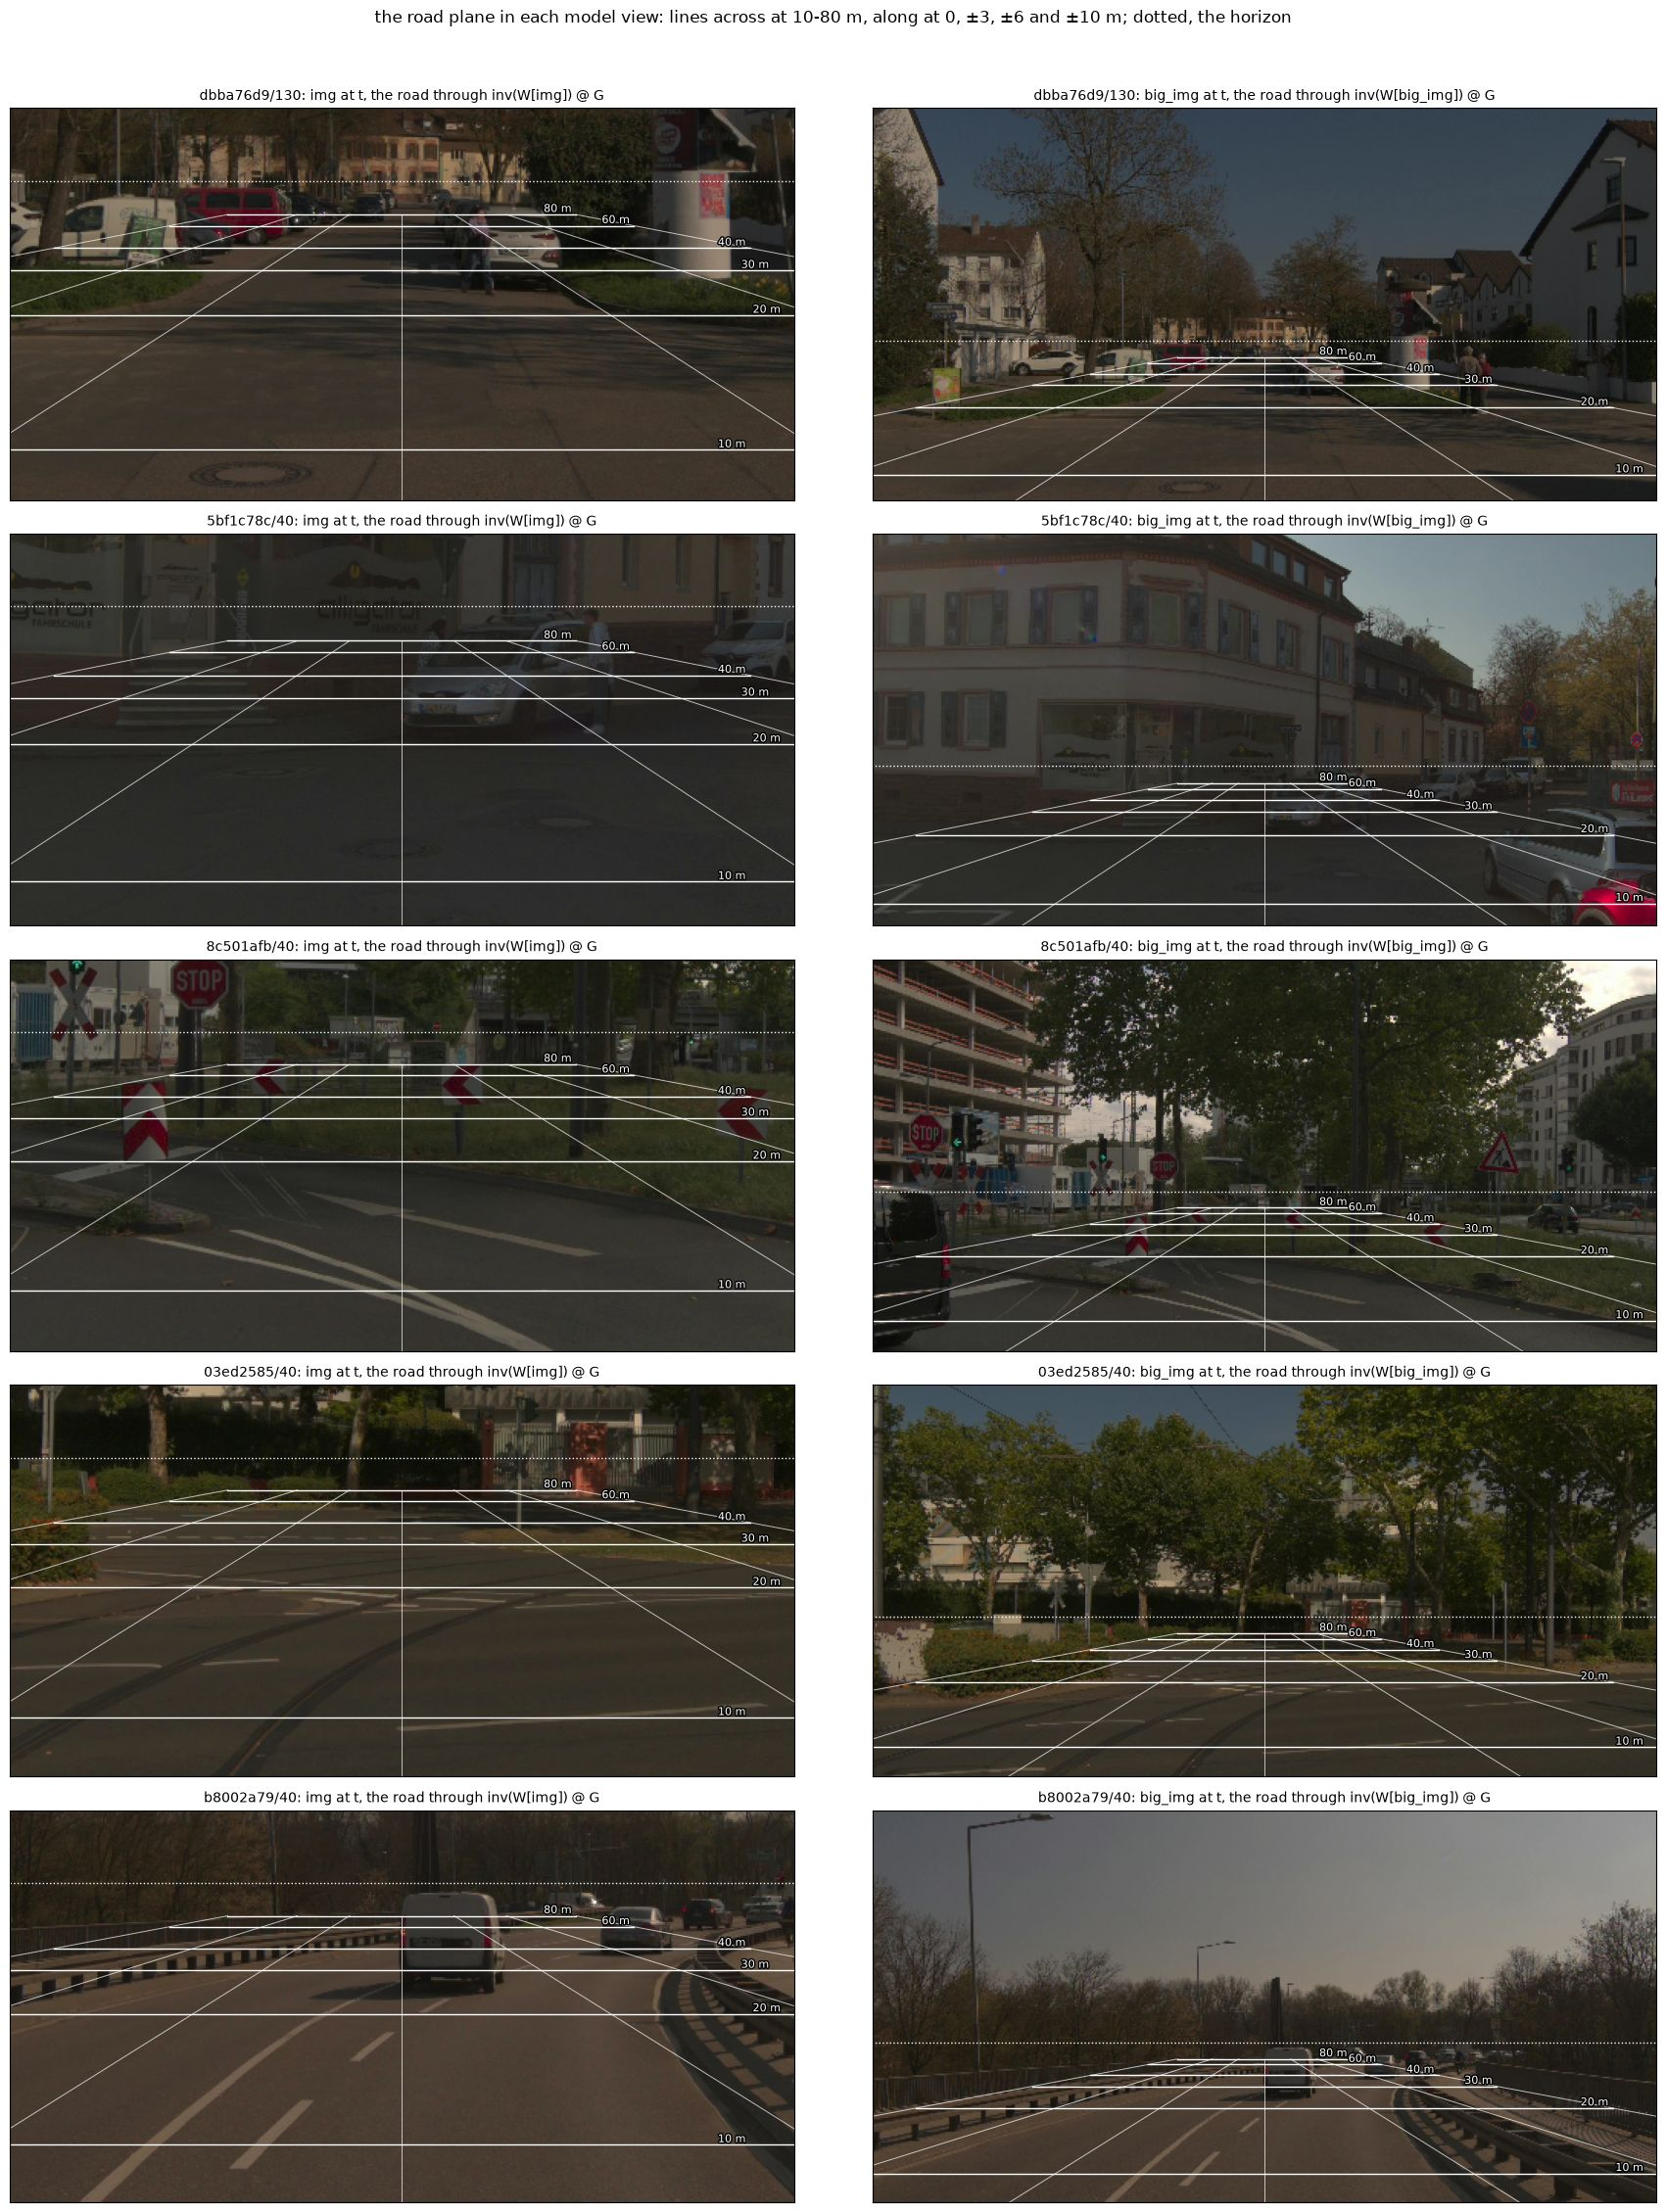

every camera's views span (right and down +): img -15.7 to +15.7 deg across, -3.0 to +12.9 down; big_img -29.4 to +29.4 deg across, -18.5 to +12.9 down


,"roll, pitch, yaw (deg)",focal length (px),img: camera px per model px,big_img: camera px per model px
key,,,,
dbba76d9/130,"+0.25, -0.04, +0.04",1841.0,2.02,4.05
5bf1c78c/40,"+0.25, -0.04, +0.04",1841.0,2.02,4.05
8c501afb/40,"+0.26, -0.11, +0.97",1841.0,2.02,4.05
03ed2585/40,"+0.26, -0.11, +0.97",1841.0,2.02,4.05
b8002a79/40,"+0.25, -0.04, +0.04",1841.0,2.02,4.05


In [5]:
lab.show_warps(FOCUS)

## 2 How the heights and speeds are measured, on one turn

`FOCUS`, 03ed2585/40, has the worst ADE of the five, and most of it is speed:
- The plan slows from 4.4 to 2.8 m/s while the car speeds up from 4.9 to 6.3 m/s (the figure's bottom right). By 3 s it has covered 10.6 m of the GT's 17.1 m.
- Covering less road, it has also turned less by 3 s: 28° of the GT's 53°, which the turn classes call understeer. Over the GT's whole length it turns as far as the GT does (`turn_frac` 1.01).
- On the way it keeps close to the GT's path: every waypoint within 3 s lies within 0.23 m of it.

The speed is robust; the exact path is not. Part 3's `noise` row shows what half-pixel shifts do to this plan: its start speed moves by 1% at most, but it can turn 9° more and move 0.42 m further from the GT's path.

The model also reads its camera as low: 1.36 m, where the map puts it at 1.87 m. Reading the camera too low and the car too slow go together, as below.

The model is told neither its height nor its speed. It reads both from the images, and two of its outputs show what it read:
- **`cam_h`**: the camera's height above the road plane, from supercombo's `road_transform` head;
- **the pose head**: the model's forward speed, from supercombo's `pose` head.

`plan_v0`, the plan's own start speed, is a separate output.

The tables below give every height and speed on this turn, with how each is measured. The figure shows how the two are linked:
- **Top row:** img's two frames, 0.2 s apart, and what changed between them. That change is all the image says about speed.
- **Bottom left:** the road 10–40 m ahead (green), and the image rows the model reads as those distances (red, dashed) at the height it reads. The plan is drawn twice: on the real road, and on the road the model reads.
    - **What geometry alone predicts** (argued). The model puts its camera at 1.36 m when it is 1.87 m up, so it reads every distance as 0.73 of the true one. It should therefore read the road between the frames as moving 0.73 as far, and so read 0.73 of the true speed.
    - **What was measured.** The pose head reads 0.71 here. Across keyframes, the note found that the speed goes as that ratio to the power 0.68, not 1.
- **Bottom right:** the speeds. The GT's and the plan's are plotted per 0.5 s step, with the readings at t = 0.

**03ed2585/40: Turn right in 28m at 4.9 m/s; camera 1.87 m over the road (the map's).** From the recorded run, 20260930T154018-242869.

**The camera's height over the road (m)**

| height | m | how it is measured |
|---|---|---|
| the harness's | 2.017 | calib.json's camera z in the rig's base frame, plus `POD_HEIGHT_M` = 2.2 m, a fixed guess at the base frame's height over the road (`_read_calibration`). openpilot never reads it: its warp is a rotation, and has no height in it. |
| the map's | 1.867 | scenario mining's `height_ring_front_m`: on each of the scene's frames on the map, the front camera's height over the Lanelet2 road surface beneath it, from the INS pose; then the median over those frames. This is the real height the notebook draws the road at. |
| **the model's** (`cam_h`) | **1.361** | `extras.road.camera_height`: the z of supercombo's `road_transform` head, where it puts the road plane below the camera, on the keyframe's tick. Nothing the model is given holds a height: it infers this from the images. |
| openpilot's own | 1.22 | comma's camera over the road, the height supercombo was trained at. |

**The speeds at t = 0 (m/s)**

| speed | m/s | how it is measured |
|---|---|---|
| ▶ **the pose speed** | **4.93** | `loader.ego_speed`: \|p(k+1) − p(k−1)\| / 0.2 s, the INS poses at 10 Hz either side of the keyframe k = 40. The right speed. |
| the pose speed over `img`'s pair | 4.92 | \|p(k) − p(k−2)\| / 0.2 s, between exactly the two frames `img` holds, 38 and 40. |
| the GT's first step | 4.91 | \|GT(0.5 s)\| / 0.5 s: where the poses put the car half a second on. |
| ◀ **the pose head** | **3.49** | `extras.pose.velocity[0]`: the forward speed from supercombo's `pose` head, on the keyframe's tick. Nothing the model is given holds a speed: it reads its motion from the images (`img` and `big_img` each hold two frames 0.2 s apart) and from its own features of earlier ticks. |
| ◆ `plan_v0` | 4.40 | `extras.plan_v0`: the plan's own velocity at t = 0, a separate output from the pose head. It is the one openpilot's longitudinal control reads. |
| the plan's first step | 4.41 | \|plan(0.5 s)\| / 0.5 s: what the score sees. |

**Ratios**

| ratio | this turn | for reference |
|---|---|---|
| `head_ratio` = ◀ / ▶ | **0.708** | 0.877 is the note's median over 205 keyframes: 0.817 where the model reads its height low (near 1.39 m), 0.915 where it reads it high (near 1.62 m). |
| `v0_ratio` = the plan's first step / the GT's | 0.899 | median 0.909 |
| ◆ / ◀ | 1.263 | median 1.024: the plan starts at about the speed the pose head reads. |
| the model's height / the map's | 0.729 | where `head_ratio` would be if the model measured distance by geometry alone: a road point X ahead is read at X · cam_h / h. |
| (the model's height / the map's)^0.68 | 0.807 | where the note's fit across keyframes puts it (exponent CI 0.62–0.75): the speed is misread less than the height. |

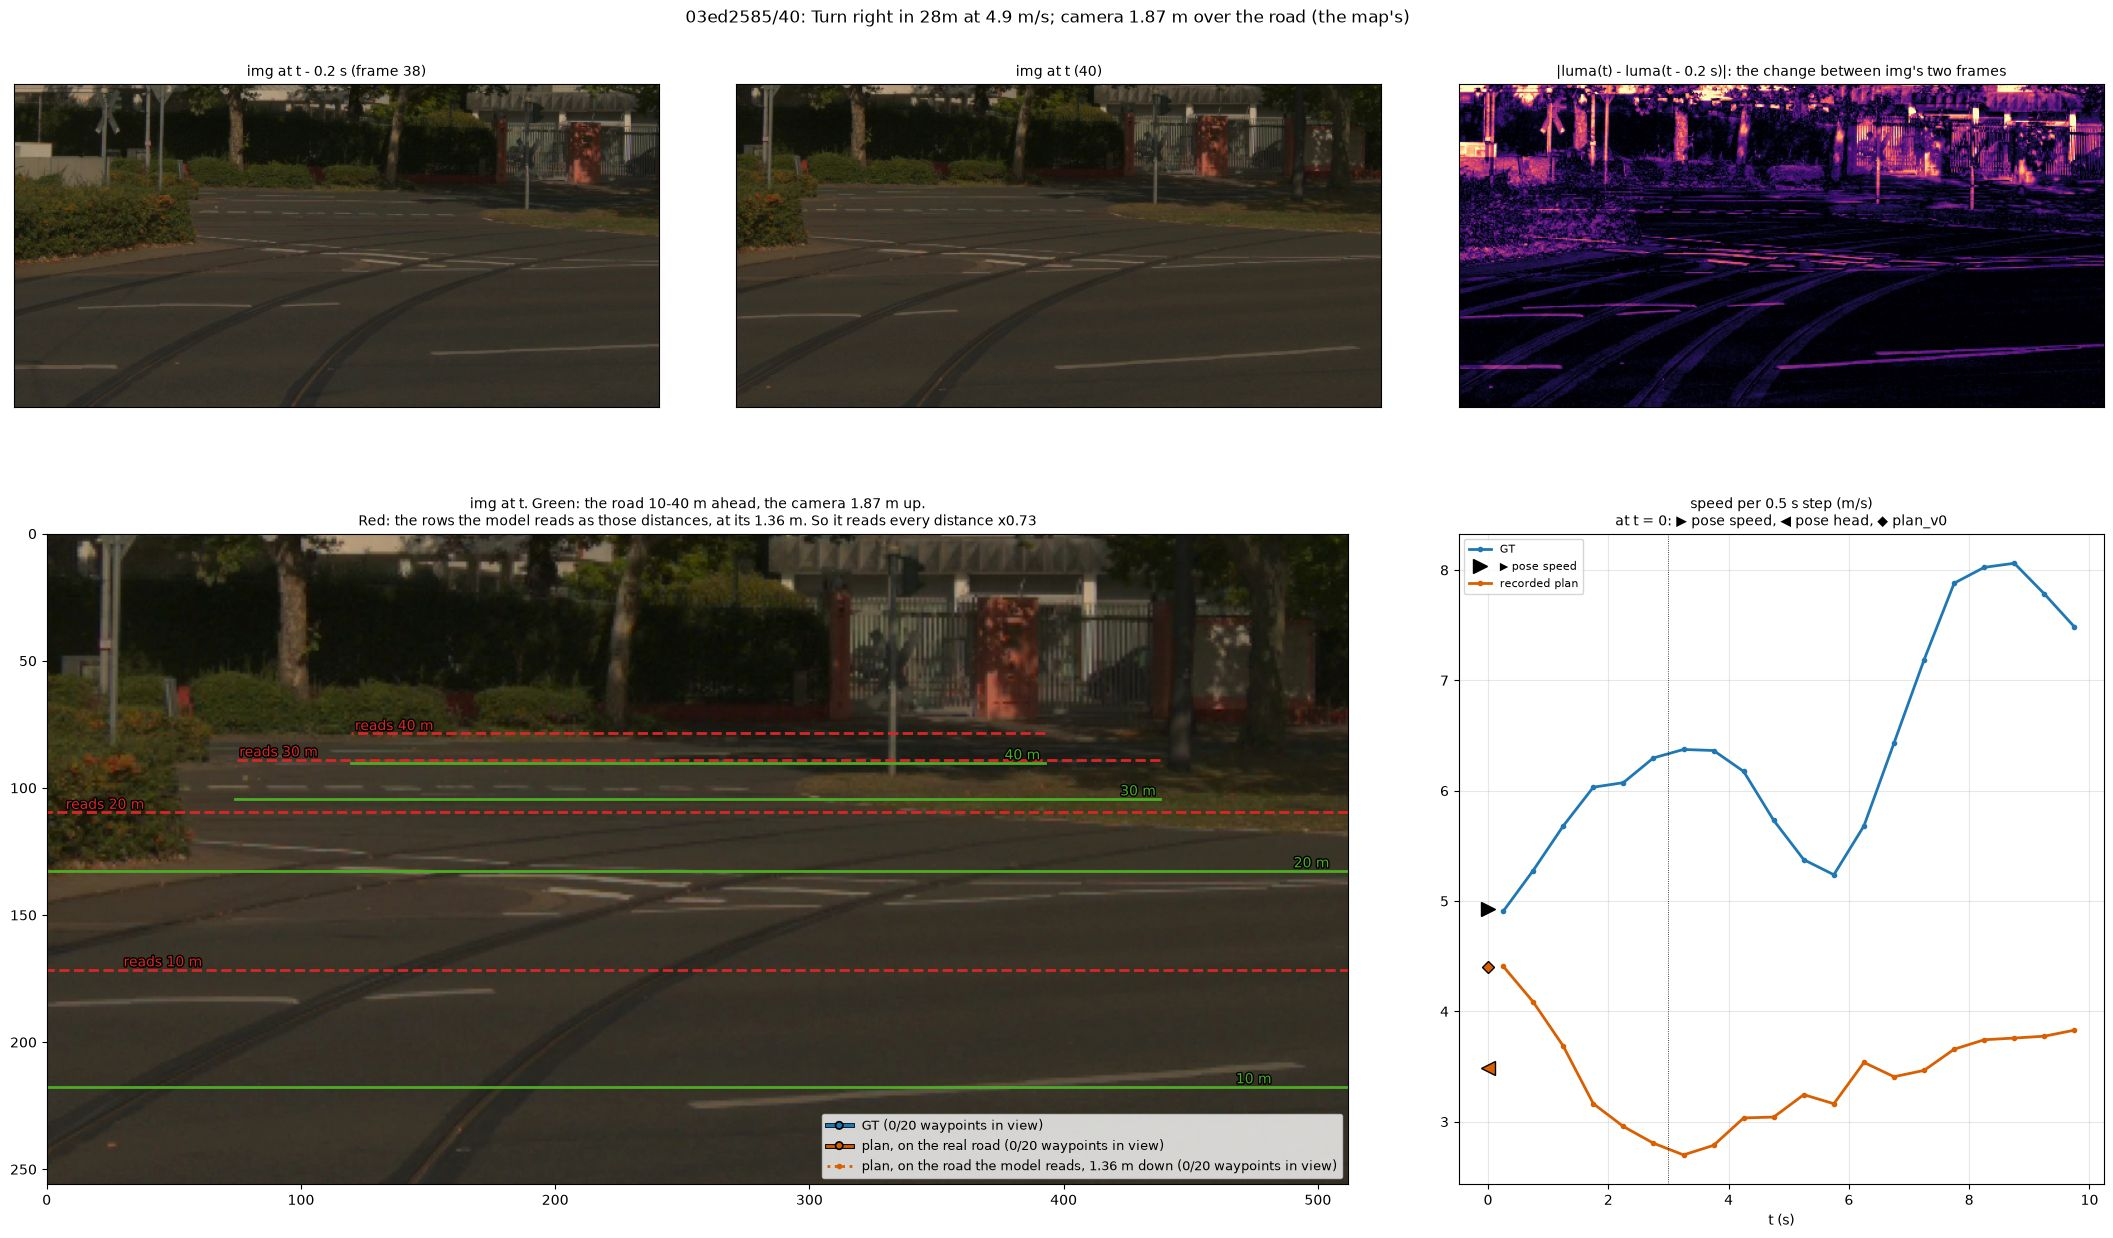

In [6]:
lab.show_measurements(FOCUS)

## Before part 3: does the node give the stock model's output?

Four checks, each of which raises an error if it fails:
1. **The node is the stock adapter.** With no config, the node gives the same plan, extras, warps and ticks as the untouched adapter, bit for bit. So does an identity config sent the way every config is sent, as `calib` and `post` matrices. So a change in the plan is the config's own, and the half-pixel shifts behind the `noise` row and part 4's floor measure the shift alone.
2. **The drawings show what the model was fed.** What this notebook draws as the model's input matches what the model received. This is checked on every path the node has: shift, supersampling, filter, tone tables and blanking.
3. **Stock run here reproduces the recorded run** on every turn, within 0.25 m over 3 s. The recorded run was made on a GPU, so the match cannot be bit for bit.
4. **The tick counts agree.** The model ticks counted here are the node's own. img's older frame is found from them.

In [7]:
lab.checks(FOCUS)

started 1 node(s) on cpu in 3 s


1. 03ed2585/40: the node with no config, against the untouched adapter, the same: {'plan': True, 'extras': True, 'warps': True, 'ticks': True}


1. 03ed2585/40: the node with an identity config, sent as configs are, against the untouched adapter, the same: {'plan': True, 'extras': True, 'warps': True, 'ticks': True}


ran 1 on 1 node(s) in 2 s (median 2.4 s each)
2. 03ed2585/40, stock, img: drawn == fed: True
2. 03ed2585/40, stock, big_img: drawn == fed: True


ran 1 on 1 node(s) in 2 s (median 2.3 s each)
2. 03ed2585/40, dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img, img: drawn == fed: True
2. 03ed2585/40, dx_px=0.5 supersample=3 sharpen=0.5 gamma=0.8 saturation=1.3 blank=img, big_img: drawn == fed: True
3 and 4. stock, run here on cpu, against 20260930T154018-242869, recorded on a GPU:


,largest difference within 3 s (m),over 10 s (m),ADE here - recorded (m),"ticks, node","ticks, counted here",img's older frame
key,,,,,,
dbba76d9/130,0.006,0.031,0.000,98,98,128 (observation -3)
5bf1c78c/40,0.010,0.055,-0.006,90,90,38 (observation -3)
8c501afb/40,0.016,0.044,0.001,90,90,38 (observation -3)
03ed2585/40,0.016,0.062,0.006,90,90,38 (observation -3)
b8002a79/40,0.016,0.125,-0.006,90,90,38 (observation -3)


## 3 Change the image on one turn

Edit `CONFIG` and run the cell. The model plans `FOCUS` again with the image changed, and the figure shows the result beside stock:
- **Top row:**
    - the keyframe, with stock's view outlines (grey) and the config's;
    - the road grid as the config shows it to the model (red), against where it really is (grey);
    - the paths seen from above.
- **Middle row:** the speed and the heading at each 0.5 s step.
- **Bottom rows:** the four images the model is given, stock's above the config's.
    - On the `OVERLAY` views, the GT and the plan are drawn.
    - Two horizons are drawn as well: the camera's (dashed) and the one the model was trained to expect (dotted).

The table under the figure gives part 1's metrics for stock, for the config, and the change between them. Its last row, **`noise`**, is the largest change that any of eight half-pixel shifts (`T.SHIFTS`) makes on this turn, with every turn class they give.
- The shifts move the geometry by almost nothing, so a change within `noise` is not the config's doing.
- They take eight runs the first time on each turn, cached after that. `lab.tweak(..., noise=False)` skips them.

**How to use it**
- Every value in `CONFIG` below leaves the image unchanged, and the knobs combine freely.
- Set **`RUN_MODEL = False`** to draw only what the model would be shown, in a second or two, without running the model.
- To run another turn, use `lab.tweak(key, CONFIG)` with any key.

| knob | what the model is shown | what it should do to the plan |
|---|---|---|
| `height_scale` s | the road as seen from a camera at h / s | every distance and width s× larger, so faster |
| `zoom` k | the image magnified k×, like a longer lens | distances ×1/k with widths unchanged, so slower when k > 1; a smaller field of view |
| `hstretch` g | the image stretched g× sideways | lateral offsets and lane widths ×g; curves look tighter |
| `yaw_deg` ψ | the view turned ψ left | the plan's heading turns ψ right |
| `turn_yaw_deg` | the view turned toward the route's side; negative turns it away | turned toward: the plan turns away from the route; turned away: the plan turns toward it |
| `pitch_deg` | the view tilted up, so the road sits lower | the road reads nearer, so slower |
| `roll_deg` | the view rolled, so the right side looks lower | the plan drifts sideways |
| `ahead_m`, `left_m` | the camera moved over the road, at the same height | the plan starts where that camera would stand |
| `dx_px`, `dy_px` | the sampling grid moved right and down, in model pixels | nothing beyond noise; half a pixel is the noise floor |
| `views` | which views the geometry applies to: `"both"`, `"img"` or `"big_img"` | |
| `supersample` n, `ss_views` | each model pixel the mean of n × n camera samples, in `ss_views` | big_img spans about 4 camera pixels per model pixel here, against 1.25 on comma's camera |
| `sharpen` α | an unsharp mask, δ + α(δ − blur) over 3 × 3; −1 is the blur itself | |
| `gamma`, `contrast`, `brightness`, `saturation` | tone, on both views: gamma on luma (below 1 is brighter); contrast about mid-grey; brightness in luma steps; saturation 0 is grey | |
| `blank` | `"img"` or `"big_img"` shown as flat grey | shows what that view contributes |

**Where to start.** These numbers come from [the note](openpilot_drv_supcombo_kitscenes_four_questions.md), measured on other keyframes:
- **Speed.**
    - On average, the pose head reads the car's speed correctly at `height_scale` 1.22 (CI 1.17–1.26), and the plan's first step matches the GT's at 1.18 (1.12–1.22).
    - Both respond less than the image changes: the head as s^0.54, the plan's first step as s^0.56.
    - This turn is in the low mode (its road head reads the camera at 1.36 m), where they respond as s^0.71 and s^0.65.
    - On this turn the two readings need different scales. The head reads 0.71 of the car's speed, but the plan starts at 0.90 of the GT's (part 2). By the low-mode exponents:
        - the plan's start would be right near s ≈ (1 / 0.90)^(1 / 0.65) ≈ 1.18;
        - the head would be right near s ≈ (1 / 0.71)^(1 / 0.71) ≈ 1.6. That is past the sweep's largest scale, 1.53, so treat 1.6 as a direction, not a value.
    - The score sees the plan, not the head. And this plan's trouble is that it slows over 3 s, so a scale that fixes its start may not fix its speed at 3 s.
- **This turn's shape is sensitive to the pixels.** All eight shifts turn its plan more than stock does, by 0.7–8.9° over 3 s. So stock sits at the low end of what the model does with this image, and a config that turns this plan a few degrees more may only be doing what any change does. Part 4 tests it on all five turns.
- **`zoom` changes distance only.** `zoom` 0.9 changes distances as `height_scale` 1.11 does, but leaves widths as they are.
- **Turning.** Across 95 image settings on ten turns, at most one more plan turned toward the route. An image change fixes the speed; it may not fix the turn.

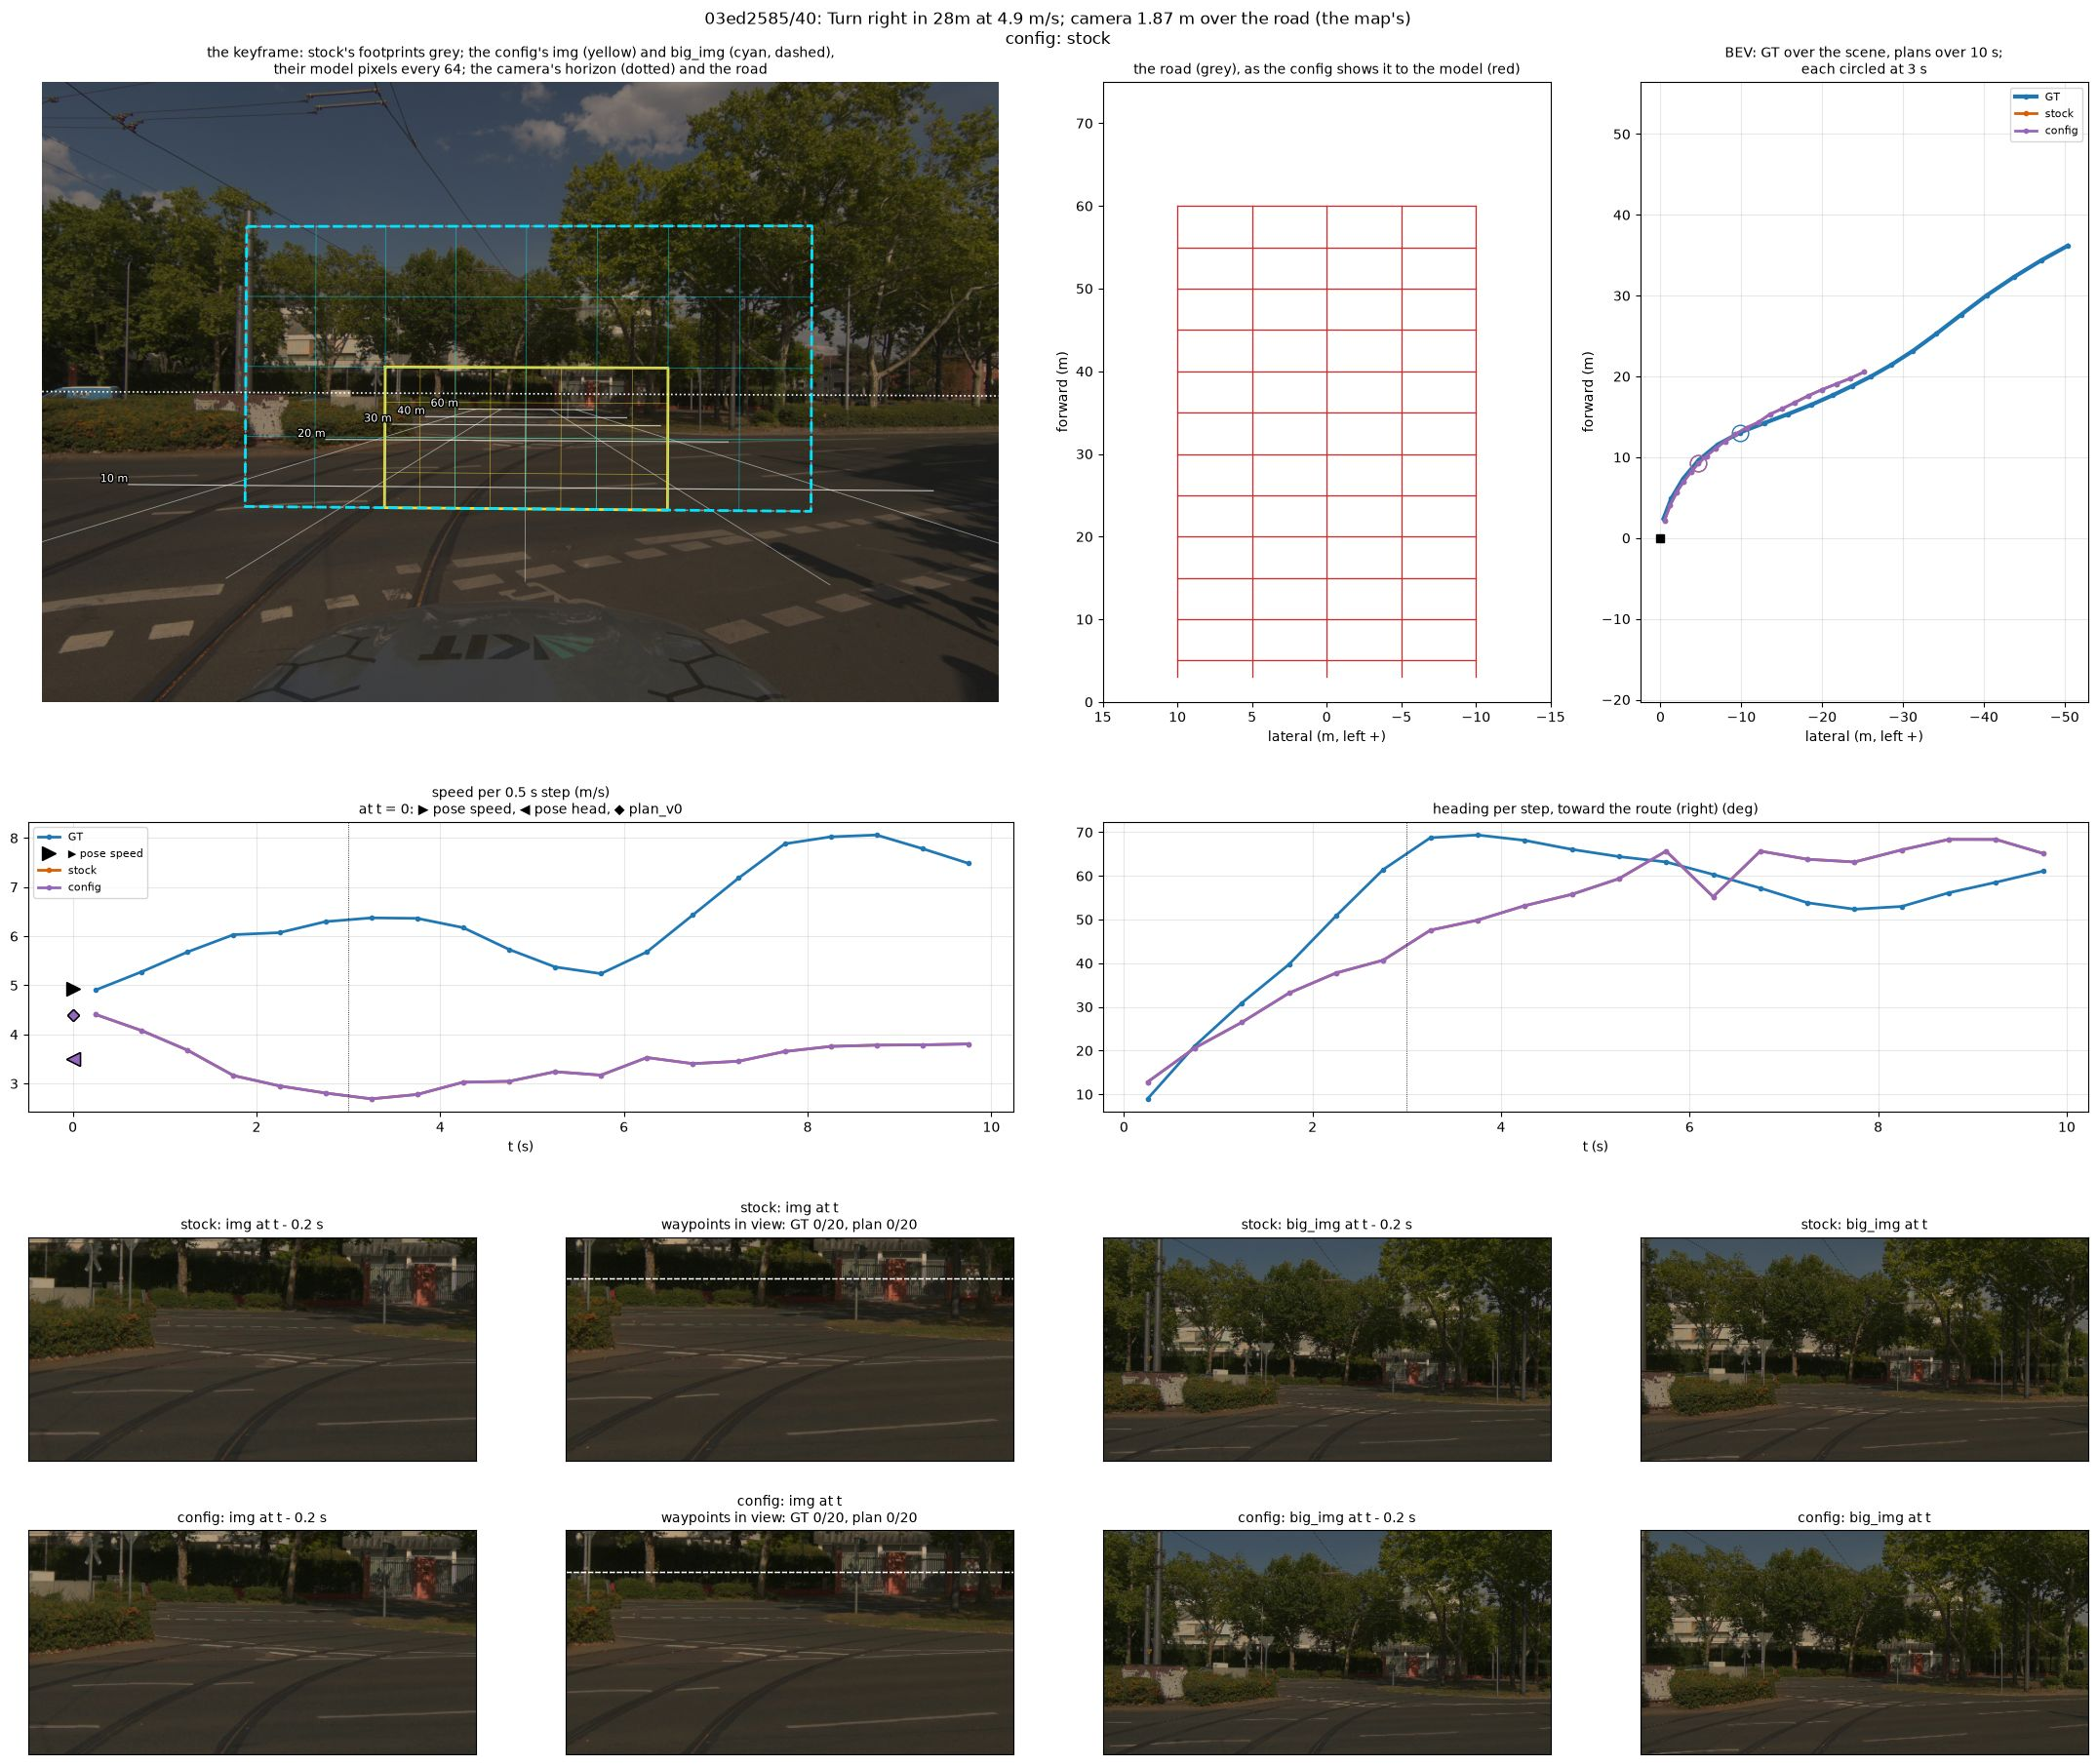

,mode,ade,ade_long,lat,lon,path_err,dpsi,gt_dpsi,dpsi_err,turn_frac,speed_rmse,v0_ratio,head_ratio,plan_v0,cam_h
stock,understeer,2.864,13.517,1.870,2.083,0.200,27.898,52.506,-24.608,1.004,2.443,0.898,0.710,4.398,1.361
config,understeer,2.864,13.517,1.870,2.083,0.200,27.898,52.506,-24.608,1.004,2.443,0.898,0.710,4.398,1.361
change,understeer -> understeer,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
noise,"matched, understeer",0.286,2.729,0.486,0.136,0.422,8.861,0.000,8.861,0.059,0.242,0.009,0.053,0.047,0.009


noise: the largest change that any of the 8 half-pixel shifts (T.SHIFTS) makes on this turn, and every class they give; a change within it is not the config's doing
the config shows a road point (X, Y) about where stock shows (X x 1.000, Y x 1.000); share of each view inside the camera frame: img 1.00, big_img 1.00


In [8]:
CONFIG = dict(
    # geometry
    height_scale=1.0,  # s: the road as from a camera at h / s
    zoom=1.0,  # k: magnified k x
    hstretch=1.0,  # g: stretched g x sideways
    yaw_deg=0.0,  # the view turned left (deg)
    turn_yaw_deg=0.0,  # the view turned toward the route's side (deg); negative is away
    pitch_deg=0.0,  # the view tilted up (deg)
    roll_deg=0.0,  # the view rolled, its right side down (deg)
    ahead_m=0.0,  # the camera moved forward (m)
    left_m=0.0,  # and left (m)
    dx_px=0.0,  # the sampling grid moved right (model pixels)
    dy_px=0.0,  # and down
    views="both",  # where the geometry applies: "both", "img" or "big_img"
    # sampling
    supersample=1,  # n: n x n camera samples per model pixel
    ss_views="big_img",  # where supersampling applies
    sharpen=0.0,  # alpha; -1 is a 3 x 3 blur
    # tone, on both views
    gamma=1.0,  # on luma; under 1 is brighter
    contrast=1.0,  # about mid-grey
    brightness=0.0,  # luma steps
    saturation=1.0,  # 0 is grey
    # ablation
    blank="",  # "img" or "big_img": that view shown as flat grey
)
RUN_MODEL = True  # False: draw what the model would be shown, without running it

lab.tweak(FOCUS, CONFIG, run=RUN_MODEL, overlay=OVERLAY)

## 4 The config on all five turns

Run this once part 3's config looks worth scoring. It plans the five turns twice, with `CONFIG` and with stock, both here. It shows:

1. **Each turn**, stock and config side by side, with the change. The columns are part 1's. `dpsi_err` is the plan's heading change over 3 s minus the GT's; it is negative when the plan turns too little.
2. **The means over the turns, with a verdict for each criterion.** Lower is better for every criterion except the count of plans that turn toward the route:

    | group | criteria |
    |---|---|
    | ADE | ADE over 3 s (the benchmark's score); ADE over the GT's whole length, up to 10 s |
    | alignment | lateral error over 3 s; distance from the GT's path over 3 s; heading error over 3 s; how many plans turn toward the route (higher is better) |
    | speed profile | RMSE of the 0.5 s step speeds over 3 s; how far the plan's start speed is from the GT's; how far the pose head's speed is from the pose speed |

3. **One verdict per group**: better, worse, mixed, or no clear change.
4. **Each turn drawn**: the paths, the speeds and the headings. Stock is orange; the config is purple.

**Read alignment with the speed profile.** The lateral and heading errors compare the plan and the GT at the same time, as the benchmark does, so a plan that is only too slow on a curve shows both. The distance from the GT's path ignores timing. In part 1's table:
- 03ed2585/40 keeps to the GT's path (`path_err` 0.19 m) but is slow, so its lateral error is 1.87 m;
- b8002a79/40 is about a tenth slower than the GT, but its sideways offset keeps pace with the GT's (`lat` 0.10 m). It reaches each offset in less distance, so it curves more tightly than the road (`path_err` 0.38 m).

**The noise floor.** Any change at all to the image moves every score a little. So a change counts only when it is bigger than what eight shifts of half a model pixel do (`T.SHIFTS`); those shifts move the geometry by almost nothing.
- **Each turn:** a turn counts as better or worse when its change exceeds the median change a shift makes on one turn.
- **The mean:** the verdict is better when the mean change exceeds the largest change any shift makes to the mean, and more turns get better than worse. Worse is the same in reverse.
- **Each group:** better when one of its criteria is better and none is worse; mixed when some are better and some worse.
- `lab.compare(CONFIG, noise=False)` counts any change at all.

The first call runs the shifts on the five turns: 40 runs, cached after that.

Five turns is a small sample. A clear verdict here is a reason to test on more turns, not a result. `SCENES` accepts any KITScenes keyframe.

**Each turn, stock and config: stock** (both run here on cpu)

ade               ade_long                   lat         \
              stock config change    stock  config change  stock config   
dbba76d9/130  2.318  2.318    0.0   10.123  10.123    0.0  1.896  1.896   
5bf1c78c/40   1.710  1.710    0.0   15.582  15.582    0.0  0.857  0.857   
8c501afb/40   0.744  0.744    0.0   15.484  15.484    0.0  0.464  0.464   
03ed2585/40   2.864  2.864    0.0   13.517  13.517    0.0  1.870  1.870   
b8002a79/40   2.132  2.132    0.0   12.607  12.607    0.0  0.098  0.098   

                    path_err               dpsi_err                turn_frac  \
             change    stock config change    stock  config change     stock   
dbba76d9/130    0.0    0.850  0.850    0.0  -60.371 -60.371    0.0    -0.002   
5bf1c78c/40     0.0    0.336  0.336    0.0  -38.391 -38.391    0.0    -0.957   
8c501afb/40     0.0    0.250  0.250    0.0  -21.619 -21.619    0.0     0.371   
03ed2585/40     0.0    0.200  0.200    0.0  -24.608 -24.608    0.0     1.004   
b8002a79/40     0.0    0.383  0.383    0.0   -0.113  -0.113    0.0     0.614   

                           speed_rmse               v0_ratio                \
             config change      stock config change    stock config change   
dbba76d9/130 -0.002    0.0      0.948  0.948    0.0    0.798  0.798    0.0   
5bf1c78c/40  -0.957    0.0      1.221  1.221    0.0    0.805  0.805    0.0   
8c501afb/40   0.371    0.0      0.413  0.413    0.0    0.792  0.792    0.0   
03ed2585/40   1.004    0.0      2.443  2.443    0.0    0.898  0.898    0.0   
b8002a79/40   0.614    0.0      1.368  1.368    0.0    0.916  0.916    0.0   

             head_ratio                cam_h                \
                  stock config change  stock config change   
dbba76d9/130      0.896  0.896    0.0  1.413  1.413    0.0   
5bf1c78c/40       0.766  0.766    0.0  1.383  1.383    0.0   
8c501afb/40       0.725  0.725    0.0  1.384  1.384    0.0   
03ed2585/40       0.710  0.710    0.0  1.361  1.361    0.0   
b8002a79/40       0.883  0.883    0.0  1.633  1.633    0.0   

                                    mode  
                         stock -> config  
dbba76d9/130  not_planned -> not_planned  
5bf1c78c/40       wrong_way -> wrong_way  
8c501afb/40     understeer -> understeer  
03ed2585/40     understeer -> understeer  
b8002a79/40           matched -> matched

**Means over the turns, and the verdict**

,judges,stock,config,change,"noise, mean","noise, per turn",better / same / worse,verdict
criterion,,,,,,,,
ADE over 3 s (m),ADE,1.953,1.953,0.0,0.026,0.064,0 / 5 / 0,no clear change
ADE over the GT's length (m),ADE,13.462,13.462,0.0,0.377,0.398,0 / 5 / 0,no clear change
lateral error over 3 s (m),alignment,1.037,1.037,0.0,0.073,0.040,0 / 5 / 0,no clear change
distance from the GT's path over 3 s (m),alignment,0.404,0.404,0.0,0.123,0.034,0 / 5 / 0,no clear change
|heading error| over 3 s (deg),alignment,29.020,29.020,0.0,1.104,0.639,0 / 5 / 0,no clear change
speed RMSE over 3 s (m/s),speed profile,1.279,1.279,0.0,0.028,0.034,0 / 5 / 0,no clear change
|1 - start speed / the GT's|,speed profile,0.158,0.158,0.0,0.004,0.004,0 / 5 / 0,no clear change
|1 - pose head / pose speed|,speed profile,0.204,0.204,0.0,0.012,0.007,0 / 5 / 0,no clear change
"turns planned toward the route (count, higher is better)",alignment,3.000,3.000,0.0,NaN,NaN,,no clear change


**stock**, against stock on 5 turns (beyond what eight half-pixel shifts do):

- **ADE: no clear change** (no clear change, no clear change)
- **alignment: no clear change** (no clear change, no clear change, no clear change, no clear change)
- **speed profile: no clear change** (no clear change, no clear change, no clear change)

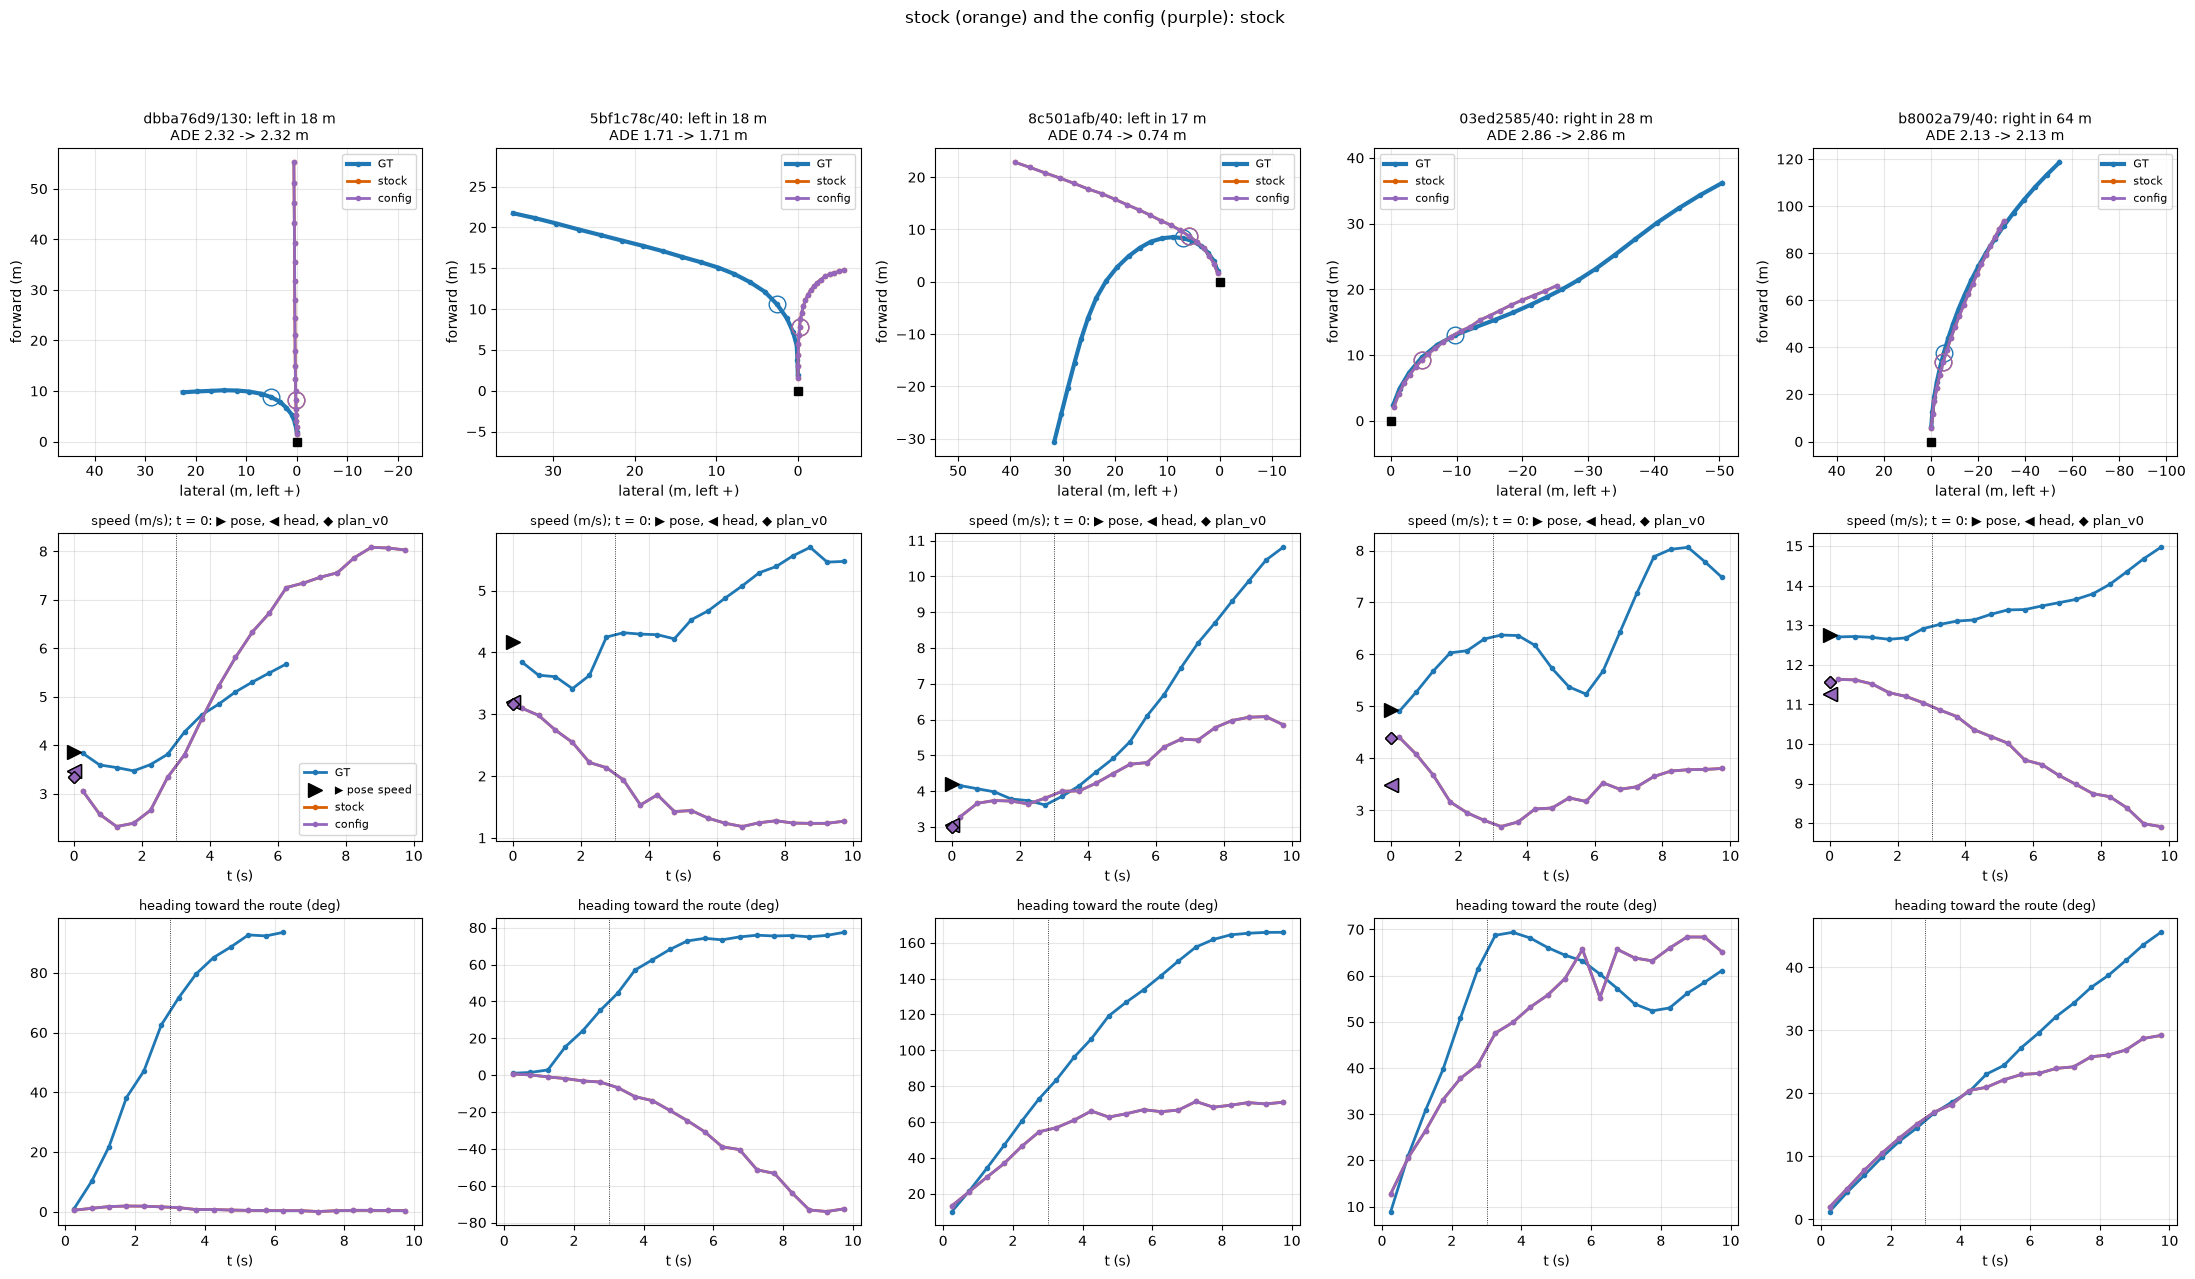

In [9]:
lab.compare(CONFIG)

## Stopping the nodes

The nodes also stop when the kernel stops, and start again on the next call that needs one.

In [10]:
lab.close()